#Loading Data

In [ ]:
import os
import shutil
import pandas as pd
import numpy as np
import random
import time
import joblib
!pip install xgboost scikit-plot optuna -q

# Correção para o erro de importação do scikit-plot com versões recentes do scipy
import scipy
scipy.interp = np.interp
import scikitplot as skplt

from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.utils import shuffle
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn import metrics
from scipy.stats import ks_2samp
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive

# 1. Conecta o seu Google Drive ao Colab
drive.mount('/content/drive')

# 2. Define os caminhos isolados para o XGBoost (reaproveitando o mesmo CSV em datasets/)
caminho_base = "/content/drive/MyDrive/Projeto_Churn_RN"
caminho_csv = os.path.join(caminho_base, "datasets", "customer_churn_telecom_services.csv")
caminho_modelos_xgb = os.path.join(caminho_base, "modelos/XGB_Entrega_V2")
caminho_logs_xgb = os.path.join(caminho_base, "logs/XGB_Entrega_V2")

pastas = [
    "",
    "datasets",
    "modelos", "modelos/XGB_Entrega_V2",
    "logs", "logs/XGB_Entrega_V2"
]

# OBSERVAÇÃO IMPORTANTÍSSIMA:
# O CAMINHO DO DRIVE ESTÁ COM _V2 COM SUFIXO
# PORQUE HAVIA SIDO RODADO ANTES UMA VERSÃO SEM O SUFIXO
# SENDO QUE APAGUEI A PRIMEIRO VERSÃO E ALTEREI O NOME
# DESSE NOTEBOOK PARA ENTREGA (SEM _V2)
# MAS PARA NÃO PRECISAR RODAR NOVAMENTE OS EXPERIEMENTOS
# MANTIVE-OS NO CAMINHO COM O NOME "ERRADO" _V2

for pasta in pastas:
    os.makedirs(os.path.join(caminho_base, pasta), exist_ok=True)

# 3. Carrega o Dataset do Drive (com fallback automático caso necessário)
try:
    df = pd.read_csv(caminho_csv)
    print("Dataset carregado do Drive com sucesso!")
except FileNotFoundError:
    !pip install kagglehub -q
    import kagglehub
    path = kagglehub.dataset_download("kapturovalexander/customers-churned-in-telecom-services")
    arquivos_csv = [f for f in os.listdir(path) if f.endswith('.csv')]
    shutil.copy(os.path.join(path, arquivos_csv[0]), caminho_csv)
    df = pd.read_csv(caminho_csv)
    print("Dataset baixado e salvo no Drive com sucesso!")

display(df.head())

Mounted at /content/drive
Dataset carregado do Drive com sucesso!


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


#Pre Processing

In [ ]:
# 0. Remoção de registros duplicados exatos (keep='first' mantém as ocorrências originais - idêntico à MLP e GB)
qtd_duplicatas = df.duplicated().sum()
print(f"Linhas antes da remoção de duplicatas: {len(df)} | Duplicatas exatas encontradas: {qtd_duplicatas}")
df = df.drop_duplicates(keep='first').reset_index(drop=True)
print(f"Linhas após manter apenas as ocorrências originais: {len(df)}\n")

# 1. Correção de tipos e Nulos (clientes novos no mês 0 -> TotalCharges = 0)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(0)

# 2. Identificando Colunas para o Pipeline
colunas_categoricas_base = df.select_dtypes(include=['object']).columns.tolist()
colunas_categoricas_base.append('SeniorCitizen')

colunas_numericas_base = df.select_dtypes(include=['int16', 'int32', 'int64', 'float16', 'float32', 'float64']).columns.tolist()
colunas_numericas_base.remove('SeniorCitizen')

# 3. Congelando a base virgem para ablação de Feature Engineering
df_base = df.copy()
print(f"Base congelada para os testes. Formato: {df_base.shape}")

Linhas antes da remoção de duplicatas: 7043 | Duplicatas exatas encontradas: 22
Linhas após manter apenas as ocorrências originais: 7021

Base congelada para os testes. Formato: (7021, 20)


#Seed

In [ ]:
def fixar_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)

#Split

In [ ]:
def realizar_split(df_input):
    """Separação 50/25/25 estratificada (100% idêntica à MLP e ao GB)."""
    df_class0 = df_input[df_input['Churn'] == 'No']
    df_class1 = df_input[df_input['Churn'] == 'Yes']

    train_0, temp_0 = train_test_split(df_class0, test_size=0.5, random_state=42)
    val_0, test_0 = train_test_split(temp_0, test_size=0.5, random_state=42)

    train_1, temp_1 = train_test_split(df_class1, test_size=0.5, random_state=42)
    val_1, test_1 = train_test_split(temp_1, test_size=0.5, random_state=42)

    df_train_out = shuffle(pd.concat([train_0, train_1]), random_state=42)
    df_val_out = shuffle(pd.concat([val_0, val_1]), random_state=42)
    df_test_out = shuffle(pd.concat([test_0, test_1]), random_state=42)
    return df_train_out, df_val_out, df_test_out

def aplicar_pipeline_e_oversampling_xgb(df_train_in, df_val_in, df_test_in, cols_cat, cols_num):
    # 1. Separar Variáveis Independentes (X) do Alvo (y)
    X_tr = df_train_in.drop('Churn', axis=1)
    y_tr = df_train_in['Churn'].map({'No': 0, 'Yes': 1})
    X_v = df_val_in.drop('Churn', axis=1)
    y_v = df_val_in['Churn'].map({'No': 0, 'Yes': 1})
    X_te = df_test_in.drop('Churn', axis=1)
    y_te = df_test_in['Churn'].map({'No': 0, 'Yes': 1})

    cat_c = [col for col in cols_cat if col != 'Churn']

    # 2. Pipeline sem normalização (árvores são invariantes à escala monotônica), fit apenas no Treino
    preprocessor = ColumnTransformer(
        transformers=[
            ('cat', OneHotEncoder(drop='if_binary', sparse_output=False), cat_c)
        ],
        remainder='passthrough',
        verbose_feature_names_out=False
    )

    X_tr_enc = preprocessor.fit_transform(X_tr)
    X_v_enc = preprocessor.transform(X_v)
    X_te_enc = preprocessor.transform(X_te)

    # Sanitiza caracteres especiais caso existam nos nomes das colunas para compatibilidade total com XGBoost
    nomes_colunas = [c.replace('[', '(').replace(']', ')').replace('<', 'lt_') for c in preprocessor.get_feature_names_out()]

    X_tr_df = pd.DataFrame(X_tr_enc, columns=nomes_colunas, index=X_tr.index)
    X_v_df = pd.DataFrame(X_v_enc, columns=nomes_colunas, index=X_v.index)
    X_te_df = pd.DataFrame(X_te_enc, columns=nomes_colunas, index=X_te.index)

    # 3. Repetitive Oversampling apenas em Treino e Validação (Teste permanece intacto e desbalanceado)
    train_full = pd.concat([X_tr_df, y_tr], axis=1)
    val_full = pd.concat([X_v_df, y_v], axis=1)

    def balancear(df_dados):
        df_0 = df_dados[df_dados['Churn'] == 0]
        df_1 = df_dados[df_dados['Churn'] == 1]
        diff = len(df_0) - len(df_1)
        if diff > 0:
            df_1_over = df_1.sample(n=diff, replace=True, random_state=42)
            return shuffle(pd.concat([df_0, df_1, df_1_over]), random_state=42)
        return df_dados

    train_bal = balancear(train_full)
    val_bal = balancear(val_full)

    X_tr_final = train_bal.drop('Churn', axis=1)
    y_tr_final = train_bal['Churn']
    X_v_final = val_bal.drop('Churn', axis=1)
    y_v_final = val_bal['Churn']

    return X_tr_final, y_tr_final, X_v_final, y_v_final, X_te_df, y_te

df_train_base, df_val_base, df_test_base = realizar_split(df_base)
X_train_xgb, y_train_xgb, X_val_xgb, y_val_xgb, X_test_xgb, y_test_xgb = aplicar_pipeline_e_oversampling_xgb(
    df_train_base, df_val_base, df_test_base, colunas_categoricas_base, colunas_numericas_base
)

print(f"Pipeline do XGBoost pronto! Tamanho das features: {X_train_xgb.shape}")
print(f"TREINO    -> Total: {len(y_train_xgb)} | No Churn (0): {sum(y_train_xgb==0)} | Churn (1): {sum(y_train_xgb==1)}")
print(f"VALIDAÇÃO -> Total: {len(y_val_xgb)} | No Churn (0): {sum(y_val_xgb==0)} | Churn (1): {sum(y_val_xgb==1)}")
print(f"TESTE     -> Total: {len(y_test_xgb)} | No Churn (0): {sum(y_test_xgb==0)} | Churn (1): {sum(y_test_xgb==1)}")

Pipeline do XGBoost pronto! Tamanho das features: (5164, 40)
TREINO    -> Total: 5164 | No Churn (0): 2582 | Churn (1): 2582
VALIDAÇÃO -> Total: 2582 | No Churn (0): 1291 | Churn (1): 1291
TESTE     -> Total: 1756 | No Churn (0): 1291 | Churn (1): 465


#Get Scores Function

In [ ]:
def get_scores_churn(targets, probs_1, threshold=0.5):
    """Calcula KS, AUROC, MSE (Brier Score), Log-Loss e métricas de classificação, além do threshold ótimo do KS."""
    predictions = (probs_1 >= threshold).astype(int)

    probs_0_class = probs_1[targets == 0]
    probs_1_class = probs_1[targets == 1]

    if len(probs_0_class) > 0 and len(probs_1_class) > 0:
        ks_stat, _ = ks_2samp(probs_0_class, probs_1_class)
    else:
        ks_stat = 0.0

    if len(np.unique(targets)) > 1:
        fpr, tpr, thresholds = metrics.roc_curve(targets, probs_1)
        optimal_idx = np.argmax(tpr - fpr)
        optimal_threshold = thresholds[optimal_idx]
    else:
        optimal_threshold = 0.5

    probs_clipped = np.clip(probs_1, 1e-7, 1 - 1e-7)
    mse = metrics.mean_squared_error(targets, probs_1)
    log_loss_val = metrics.log_loss(targets, probs_clipped) if len(np.unique(targets)) > 1 else 0.0

    return {
        "accuracy": metrics.accuracy_score(targets, predictions),
        "precision": metrics.precision_score(targets, predictions, zero_division=0),
        "recall": metrics.recall_score(targets, predictions, zero_division=0),
        "f1_score": metrics.f1_score(targets, predictions, zero_division=0),
        "roc_auc": metrics.roc_auc_score(targets, probs_1) if len(np.unique(targets)) > 1 else 0.0,
        "ks_stat": ks_stat,
        "mse": mse,
        "log_loss": log_loss_val,
        "optimal_threshold": optimal_threshold
    }

#Training Function

In [ ]:
def executar_experimento_xgb(
    name_experiment,
    learning_rate=0.05,
    n_estimators=1000,
    max_depth=3,
    min_child_weight=20,
    subsample=0.8,
    colsample_bytree=0.8,
    colsample_bylevel=1.0,
    gamma=0.0,
    reg_alpha=0.0,
    reg_lambda=1.0,
    X_train=None,
    y_train=None,
    X_val=None,
    y_val=None,
    patience=20
):
    start_time = time.time()
    fixar_seed(42)
    print(f"\n{'-'*120}")
    print(f"EXP XGB: {name_experiment} | LR: {learning_rate:.4f} | Est: {n_estimators} | Depth: {max_depth} | MinChildW: {min_child_weight} | Sub: {subsample:.2f} | ColTree: {colsample_bytree:.2f} | L2: {reg_lambda:.2f}")

    # XGBClassifier com histograma rápido (tree_method='hist') e Early Stopping nativo na validação externa (logloss)
    modelo_xgb = XGBClassifier(
        objective='binary:logistic',
        eval_metric='logloss',
        tree_method='hist',
        early_stopping_rounds=patience,
        learning_rate=learning_rate,
        n_estimators=n_estimators,
        max_depth=max_depth,
        min_child_weight=min_child_weight,
        subsample=subsample,
        colsample_bytree=colsample_bytree,
        colsample_bylevel=colsample_bylevel,
        gamma=gamma,
        reg_alpha=reg_alpha,
        reg_lambda=reg_lambda,
        random_state=42,
        n_jobs=-1
    )

    modelo_xgb.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        verbose=False
    )

    # predict_proba utiliza automaticamente a melhor árvore (best_iteration) encontrada pelo Early Stopping
    probs_train = modelo_xgb.predict_proba(X_train)[:, 1]
    probs_val = modelo_xgb.predict_proba(X_val)[:, 1]

    scores_train = get_scores_churn(np.array(y_train), probs_train)
    scores_val = get_scores_churn(np.array(y_val), probs_val)

    best_iter = getattr(modelo_xgb, 'best_iteration', n_estimators - 1) + 1
    best_val_loss = scores_val['log_loss']
    val_ks = scores_val['ks_stat']
    val_auc = scores_val['roc_auc']
    train_mse = scores_train['mse']
    val_mse = scores_val['mse']

    caminho_arquivo = os.path.join(caminho_modelos_xgb, f'{name_experiment}.joblib')
    joblib.dump(modelo_xgb, caminho_arquivo)

    tempo_execucao = time.time() - start_time
    print(f"Resultados: Val Loss: {best_val_loss:.4f} | KS: {val_ks:.4f} | AUC: {val_auc:.4f} | Train MSE: {train_mse:.4f} | Val MSE: {val_mse:.4f} | F1: {scores_val['f1_score']:.4f} | Tempo: {tempo_execucao:.2f}s")
    print(f"Árvores mantidas (Early Stopping Externo): {best_iter} / {n_estimators}")

    return {
        'nome': name_experiment,
        'val_loss': best_val_loss,
        'val_ks': val_ks,
        'val_auc': val_auc,
        'train_mse': train_mse,
        'val_mse': val_mse,
        'val_acc': scores_val['accuracy'],
        'val_prec': scores_val['precision'],
        'val_rec': scores_val['recall'],
        'val_f1': scores_val['f1_score'],
        'best_n_estimators': best_iter,
        'learning_rate': learning_rate,
        'n_estimators': n_estimators,
        'max_depth': max_depth,
        'min_child_weight': min_child_weight,
        'subsample': subsample,
        'colsample_bytree': colsample_bytree,
        'colsample_bylevel': colsample_bylevel,
        'gamma': gamma,
        'reg_alpha': reg_alpha,
        'reg_lambda': reg_lambda,
        'tempo_execucao': tempo_execucao
    }

# Winner Function

In [ ]:
from sklearn.metrics import RocCurveDisplay, confusion_matrix, classification_report

def plotar_vencedor_xgb(resultados_do_bloco, X_val, y_val):
    vencedor = max(resultados_do_bloco, key=lambda x: x['val_ks'])
    print(f"\n{'='*90}")
    print(f"VENCEDOR DA BATERIA: {vencedor['nome']} (KS Máximo: {vencedor['val_ks']:.4f})")
    print(f"{'='*90}")

    caminho_arquivo = os.path.join(caminho_modelos_xgb, f"{vencedor['nome']}.joblib")
    modelo = joblib.load(caminho_arquivo)

    probs_1 = modelo.predict_proba(X_val)[:, 1]
    y_true = np.array(y_val)

    scores_default = get_scores_churn(y_true, probs_1, threshold=0.5)
    optimal_threshold = scores_default['optimal_threshold']
    scores_optimal = get_scores_churn(y_true, probs_1, threshold=optimal_threshold)

    probs_0 = 1 - probs_1
    y_pred_scores = np.column_stack((probs_0, probs_1))

    y_pred_class_default = (probs_1 >= 0.5).astype(int)
    y_pred_class_optimal = (probs_1 >= optimal_threshold).astype(int)

    fig, axes = plt.subplots(1, 4, figsize=(22, 5))
    skplt.metrics.plot_ks_statistic(y_true, y_pred_scores, ax=axes[0], title=f"KS: {vencedor['nome']}")

    RocCurveDisplay.from_predictions(y_true, probs_1, ax=axes[1], name=vencedor['nome'])
    axes[1].set_title(f"Curva ROC: {vencedor['nome']}")
    axes[1].plot([0, 1], [0, 1], 'k--', label='Aleatório')
    axes[1].legend()

    cm_default = confusion_matrix(y_true, y_pred_class_default, normalize='true')
    sns.heatmap(cm_default, annot=True, fmt=".2%", cmap="Blues", ax=axes[2],
                xticklabels=['Não Churn (0)', 'Churn (1)'], yticklabels=['Não Churn (0)', 'Churn (1)'])
    axes[2].set_title("Matriz (Thr: 0.500)")
    axes[2].set_ylabel("Valor Real")
    axes[2].set_xlabel("Predição")

    cm_optimal = confusion_matrix(y_true, y_pred_class_optimal, normalize='true')
    sns.heatmap(cm_optimal, annot=True, fmt=".2%", cmap="Greens", ax=axes[3],
                xticklabels=['Não Churn (0)', 'Churn (1)'], yticklabels=['Não Churn (0)', 'Churn (1)'])
    axes[3].set_title(f"Matriz (Thr KS: {optimal_threshold:.3f})")
    axes[3].set_ylabel("Valor Real")
    axes[3].set_xlabel("Predição")

    plt.tight_layout()
    plt.show()

    print(f"--- MÉTRICAS COM THRESHOLD PADRÃO (0.500) ---")
    print(f"KS: {scores_default['ks_stat']:.4f} | AUROC: {scores_default['roc_auc']:.4f} | MSE: {scores_default['mse']:.4f} | Log-Loss: {scores_default['log_loss']:.4f} | Acurácia: {scores_default['accuracy']:.4f}")
    print(f"Precisão: {scores_default['precision']:.4f} | Recall: {scores_default['recall']:.4f} | F1-Score: {scores_default['f1_score']:.4f}\n")
    print(classification_report(y_true, y_pred_class_default, target_names=['Não Churn (0)', 'Churn (1)']))

    print(f"\n--- MÉTRICAS COM THRESHOLD OTIMIZADO PELO KS ({optimal_threshold:.3f}) ---")
    print(f"KS: {scores_optimal['ks_stat']:.4f} | AUROC: {scores_optimal['roc_auc']:.4f} | Acurácia: {scores_optimal['accuracy']:.4f}")
    print(f"Precisão: {scores_optimal['precision']:.4f} | Recall: {scores_optimal['recall']:.4f} | F1-Score: {scores_optimal['f1_score']:.4f}\n")
    print(classification_report(y_true, y_pred_class_optimal, target_names=['Não Churn (0)', 'Churn (1)']))

    return vencedor

#Plotando Evolução Parâmetros

In [ ]:
def plotar_evolucao_parametros(df_resultados, parametro_x):
    """Plota evolução de KS (Validação) e MSE (Treino vs Validação) + tabela resumo para cada bateria."""
    df_plot = df_resultados.copy()
    df_plot[f'{parametro_x}_str'] = df_plot[parametro_x].astype(str)

    tem_mse = 'train_mse' in df_plot.columns and 'val_mse' in df_plot.columns
    cols_tabela = [parametro_x, 'val_ks', 'train_mse', 'val_mse', 'val_loss'] if tem_mse else [parametro_x, 'val_ks']
    display(df_plot[cols_tabela].round(4))

    fig, axes = plt.subplots(1, 2, figsize=(16, 5))

    max_ks = df_plot['val_ks'].max()
    cores = ['green' if ks == max_ks else 'steelblue' for ks in df_plot['val_ks']]
    sns.barplot(data=df_plot, x=f'{parametro_x}_str', y='val_ks', hue=f'{parametro_x}_str',
                palette=cores, legend=False, ax=axes[0])
    for p in axes[0].patches:
        if p.get_height() > 0:
            axes[0].annotate(format(p.get_height(), '.4f'),
                             (p.get_x() + p.get_width() / 2., p.get_height()),
                             ha='center', va='center', xytext=(0, 8), textcoords='offset points', fontsize=9)
    axes[0].set_ylim(0, max_ks * 1.18)
    axes[0].set_title(f'Comparativo de KS por {parametro_x.replace("_", " ").title()}', fontsize=13)
    axes[0].set_xlabel(parametro_x.replace('_', ' ').title(), fontsize=11)
    axes[0].set_ylabel('KS (Validação)', fontsize=11, fontweight='bold')
    axes[0].grid(axis='y', linestyle='--', alpha=0.6)
    axes[0].tick_params(axis='x', rotation=45)

    df_mse = df_plot[[f'{parametro_x}_str', 'train_mse', 'val_mse']].melt(
        id_vars=f'{parametro_x}_str',
        value_vars=['train_mse', 'val_mse'],
        var_name='Conjunto',
        value_name='MSE'
    )
    df_mse['Conjunto'] = df_mse['Conjunto'].map({'train_mse': 'Treino', 'val_mse': 'Validação'})
    sns.barplot(data=df_mse, x=f'{parametro_x}_str', y='MSE', hue='Conjunto',
                palette={'Treino': '#4C72B0', 'Validação': '#DD8452'}, ax=axes[1])
    for p in axes[1].patches:
        if p.get_height() > 0:
            axes[1].annotate(format(p.get_height(), '.4f'),
                             (p.get_x() + p.get_width() / 2., p.get_height()),
                             ha='center', va='center', xytext=(0, 8), textcoords='offset points', fontsize=8)
    axes[1].set_ylim(0, df_mse['MSE'].max() * 1.18)
    axes[1].set_title(f'MSE (Treino vs Validação) por {parametro_x.replace("_", " ").title()}', fontsize=13)
    axes[1].set_xlabel(parametro_x.replace('_', ' ').title(), fontsize=11)
    axes[1].set_ylabel('MSE (Menor é Melhor)', fontsize=11, fontweight='bold')
    axes[1].grid(axis='y', linestyle='--', alpha=0.6)
    axes[1].tick_params(axis='x', rotation=45)
    axes[1].legend(title='Conjunto')

    plt.tight_layout()
    plt.show()

### Bateria 1: Testando Quantidade Máxima de Árvores (`n_estimators`)

Iniciando Bateria 1: n_estimators...

------------------------------------------------------------------------------------------------------------------------
EXP XGB: XGB_B1_nest_100 | LR: 0.0500 | Est: 100 | Depth: 3 | MinChildW: 20 | Sub: 0.80 | ColTree: 0.80 | L2: 1.00
Resultados: Val Loss: 0.4895 | KS: 0.5515 | AUC: 0.8456 | Train MSE: 0.1439 | Val MSE: 0.1593 | F1: 0.7777 | Tempo: 0.58s
Árvores mantidas (Early Stopping Externo): 100 / 100

------------------------------------------------------------------------------------------------------------------------
EXP XGB: XGB_B1_nest_300 | LR: 0.0500 | Est: 300 | Depth: 3 | MinChildW: 20 | Sub: 0.80 | ColTree: 0.80 | L2: 1.00
Resultados: Val Loss: 0.4894 | KS: 0.5523 | AUC: 0.8459 | Train MSE: 0.1436 | Val MSE: 0.1592 | F1: 0.7794 | Tempo: 1.47s
Árvores mantidas (Early Stopping Externo): 103 / 300

------------------------------------------------------------------------------------------------------------------------
EXP XGB: XGB_B1_n

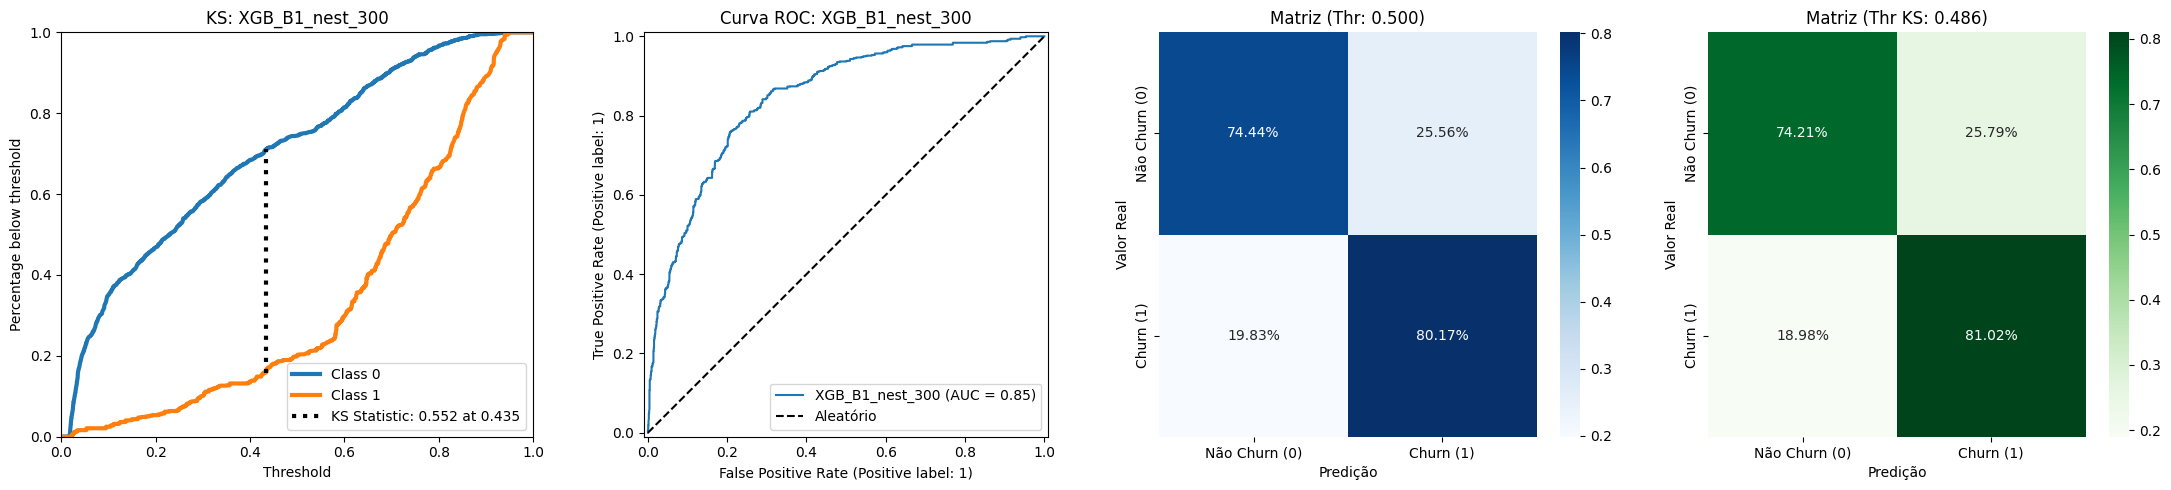

--- MÉTRICAS COM THRESHOLD PADRÃO (0.500) ---
KS: 0.5523 | AUROC: 0.8459 | MSE: 0.1592 | Log-Loss: 0.4894 | Acurácia: 0.7730
Precisão: 0.7582 | Recall: 0.8017 | F1-Score: 0.7794

               precision    recall  f1-score   support

Não Churn (0)       0.79      0.74      0.77      1291
    Churn (1)       0.76      0.80      0.78      1291

     accuracy                           0.77      2582
    macro avg       0.77      0.77      0.77      2582
 weighted avg       0.77      0.77      0.77      2582


--- MÉTRICAS COM THRESHOLD OTIMIZADO PELO KS (0.486) ---
KS: 0.5523 | AUROC: 0.8459 | Acurácia: 0.7761
Precisão: 0.7585 | Recall: 0.8102 | F1-Score: 0.7835

               precision    recall  f1-score   support

Não Churn (0)       0.80      0.74      0.77      1291
    Churn (1)       0.76      0.81      0.78      1291

     accuracy                           0.78      2582
    macro avg       0.78      0.78      0.78      2582
 weighted avg       0.78      0.78      0.78      258

,n_estimators,val_ks,train_mse,val_mse,val_loss
0,100,0.5515,0.1439,0.1593,0.4895
1,300,0.5523,0.1436,0.1592,0.4894
2,500,0.5523,0.1436,0.1592,0.4894
3,1000,0.5523,0.1436,0.1592,0.4894
4,1500,0.5523,0.1436,0.1592,0.4894
5,2500,0.5523,0.1436,0.1592,0.4894


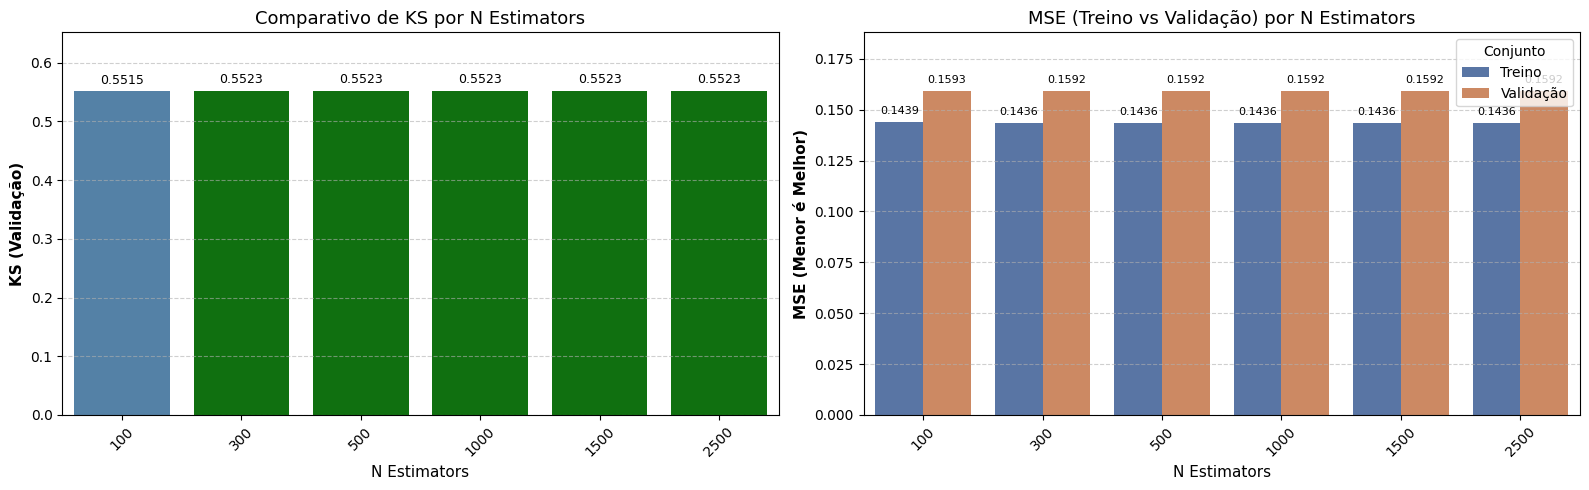

In [ ]:
print("Iniciando Bateria 1: n_estimators...")
resultados_b1 = []
for n in [100, 300, 500, 1000, 1500, 2500]:
    res = executar_experimento_xgb(
        name_experiment=f"XGB_B1_nest_{n}",
        learning_rate=0.05, n_estimators=n, max_depth=3, min_child_weight=20,
        subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
        X_train=X_train_xgb, y_train=y_train_xgb, X_val=X_val_xgb, y_val=y_val_xgb
    )
    resultados_b1.append(res)

df_resultados_b1 = pd.DataFrame(resultados_b1)
df_resultados_b1.to_csv(os.path.join(caminho_logs_xgb, "bateria_1_n_estimators.csv"), index=False)
vencedor_b1 = plotar_vencedor_xgb(resultados_b1, X_val_xgb, y_val_xgb)
plotar_evolucao_parametros(df_resultados_b1, 'n_estimators')

### Bateria 2: Testando Taxa de Aprendizado (`learning_rate`)

Iniciando Bateria 2: learning_rate...

------------------------------------------------------------------------------------------------------------------------
EXP XGB: XGB_B2_lr_0.005 | LR: 0.0050 | Est: 300 | Depth: 3 | MinChildW: 20 | Sub: 0.80 | ColTree: 0.80 | L2: 1.00
Resultados: Val Loss: 0.5205 | KS: 0.5407 | AUC: 0.8347 | Train MSE: 0.1614 | Val MSE: 0.1709 | F1: 0.7794 | Tempo: 1.50s
Árvores mantidas (Early Stopping Externo): 300 / 300

------------------------------------------------------------------------------------------------------------------------
EXP XGB: XGB_B2_lr_0.01 | LR: 0.0100 | Est: 300 | Depth: 3 | MinChildW: 20 | Sub: 0.80 | ColTree: 0.80 | L2: 1.00
Resultados: Val Loss: 0.4953 | KS: 0.5523 | AUC: 0.8426 | Train MSE: 0.1495 | Val MSE: 0.1618 | F1: 0.7790 | Tempo: 1.92s
Árvores mantidas (Early Stopping Externo): 300 / 300

------------------------------------------------------------------------------------------------------------------------
EXP XGB: XGB_B2_l

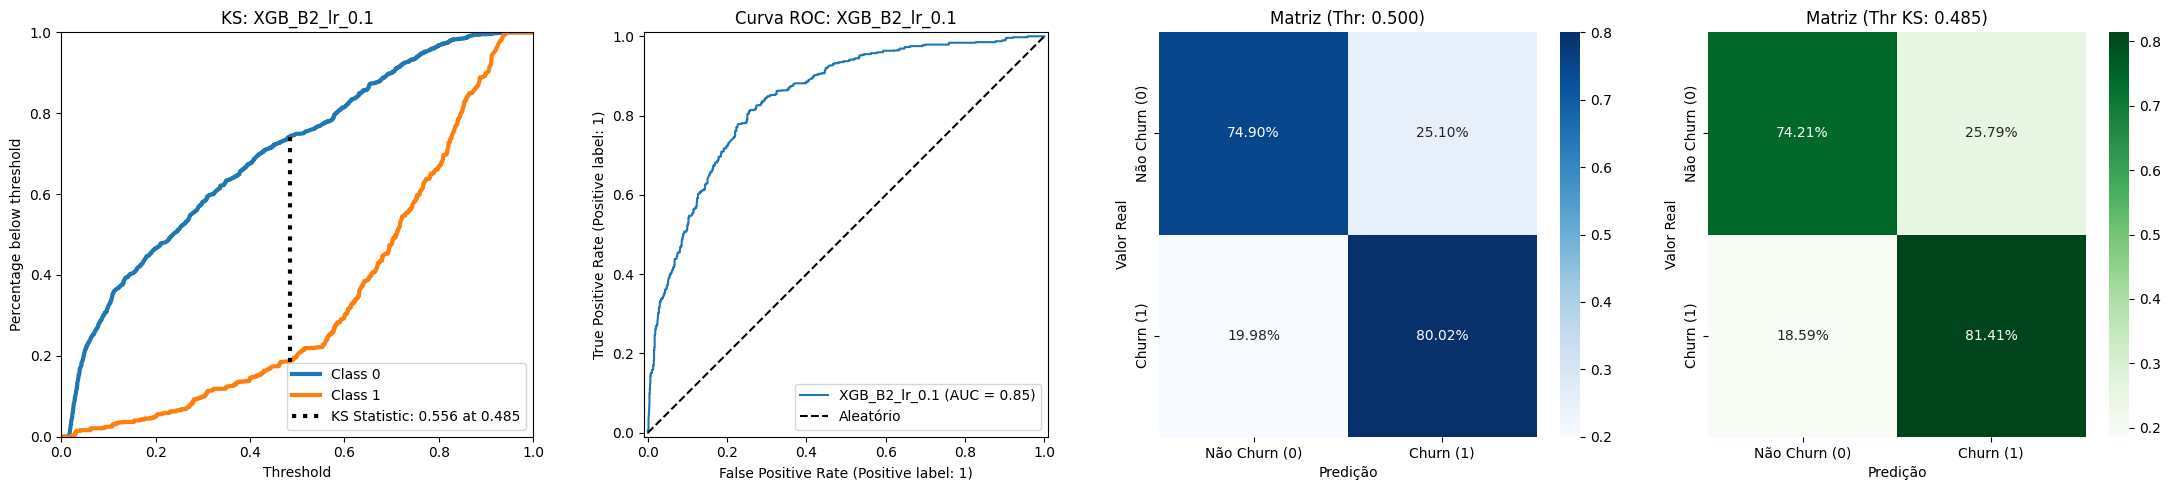

--- MÉTRICAS COM THRESHOLD PADRÃO (0.500) ---
KS: 0.5562 | AUROC: 0.8450 | MSE: 0.1597 | Log-Loss: 0.4902 | Acurácia: 0.7746
Precisão: 0.7612 | Recall: 0.8002 | F1-Score: 0.7802

               precision    recall  f1-score   support

Não Churn (0)       0.79      0.75      0.77      1291
    Churn (1)       0.76      0.80      0.78      1291

     accuracy                           0.77      2582
    macro avg       0.78      0.77      0.77      2582
 weighted avg       0.78      0.77      0.77      2582


--- MÉTRICAS COM THRESHOLD OTIMIZADO PELO KS (0.485) ---
KS: 0.5562 | AUROC: 0.8450 | Acurácia: 0.7781
Precisão: 0.7594 | Recall: 0.8141 | F1-Score: 0.7858

               precision    recall  f1-score   support

Não Churn (0)       0.80      0.74      0.77      1291
    Churn (1)       0.76      0.81      0.79      1291

     accuracy                           0.78      2582
    macro avg       0.78      0.78      0.78      2582
 weighted avg       0.78      0.78      0.78      258

,learning_rate,val_ks,train_mse,val_mse,val_loss
0,0.005,0.5407,0.1614,0.1709,0.5205
1,0.010,0.5523,0.1495,0.1618,0.4953
2,0.030,0.5546,0.1434,0.1591,0.4891
3,0.050,0.5523,0.1436,0.1592,0.4894
4,0.100,0.5562,0.1444,0.1597,0.4902
5,0.200,0.5562,0.1471,0.1599,0.4907


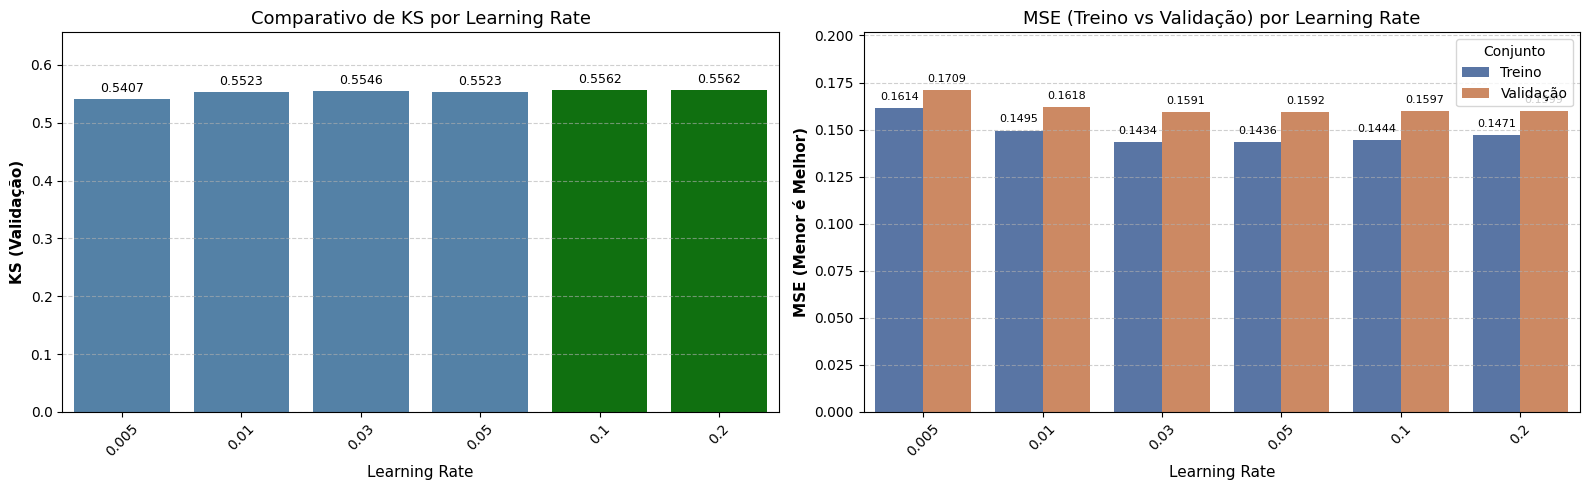

In [ ]:
print("Iniciando Bateria 2: learning_rate...")
resultados_b2 = []
melhor_n_est = vencedor_b1['n_estimators']

for lr in [0.005, 0.01, 0.03, 0.05, 0.1, 0.2]:
    res = executar_experimento_xgb(
        name_experiment=f"XGB_B2_lr_{lr}",
        learning_rate=lr, n_estimators=melhor_n_est, max_depth=3, min_child_weight=20,
        subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
        X_train=X_train_xgb, y_train=y_train_xgb, X_val=X_val_xgb, y_val=y_val_xgb
    )
    resultados_b2.append(res)

df_resultados_b2 = pd.DataFrame(resultados_b2)
df_resultados_b2.to_csv(os.path.join(caminho_logs_xgb, "bateria_2_learning_rate.csv"), index=False)
vencedor_b2 = plotar_vencedor_xgb(resultados_b2, X_val_xgb, y_val_xgb)
plotar_evolucao_parametros(df_resultados_b2, 'learning_rate')

### Bateria 3: Testando Profundidade Máxima (`max_depth`)

Iniciando Bateria 3: max_depth...

------------------------------------------------------------------------------------------------------------------------
EXP XGB: XGB_B3_depth_1 | LR: 0.1000 | Est: 300 | Depth: 1 | MinChildW: 20 | Sub: 0.80 | ColTree: 0.80 | L2: 1.00
Resultados: Val Loss: 0.4830 | KS: 0.5585 | AUC: 0.8484 | Train MSE: 0.1520 | Val MSE: 0.1572 | F1: 0.7809 | Tempo: 1.71s
Árvores mantidas (Early Stopping Externo): 193 / 300

------------------------------------------------------------------------------------------------------------------------
EXP XGB: XGB_B3_depth_2 | LR: 0.1000 | Est: 300 | Depth: 2 | MinChildW: 20 | Sub: 0.80 | ColTree: 0.80 | L2: 1.00
Resultados: Val Loss: 0.4875 | KS: 0.5538 | AUC: 0.8464 | Train MSE: 0.1500 | Val MSE: 0.1588 | F1: 0.7771 | Tempo: 0.87s
Árvores mantidas (Early Stopping Externo): 62 / 300

------------------------------------------------------------------------------------------------------------------------
EXP XGB: XGB_B3_depth_3

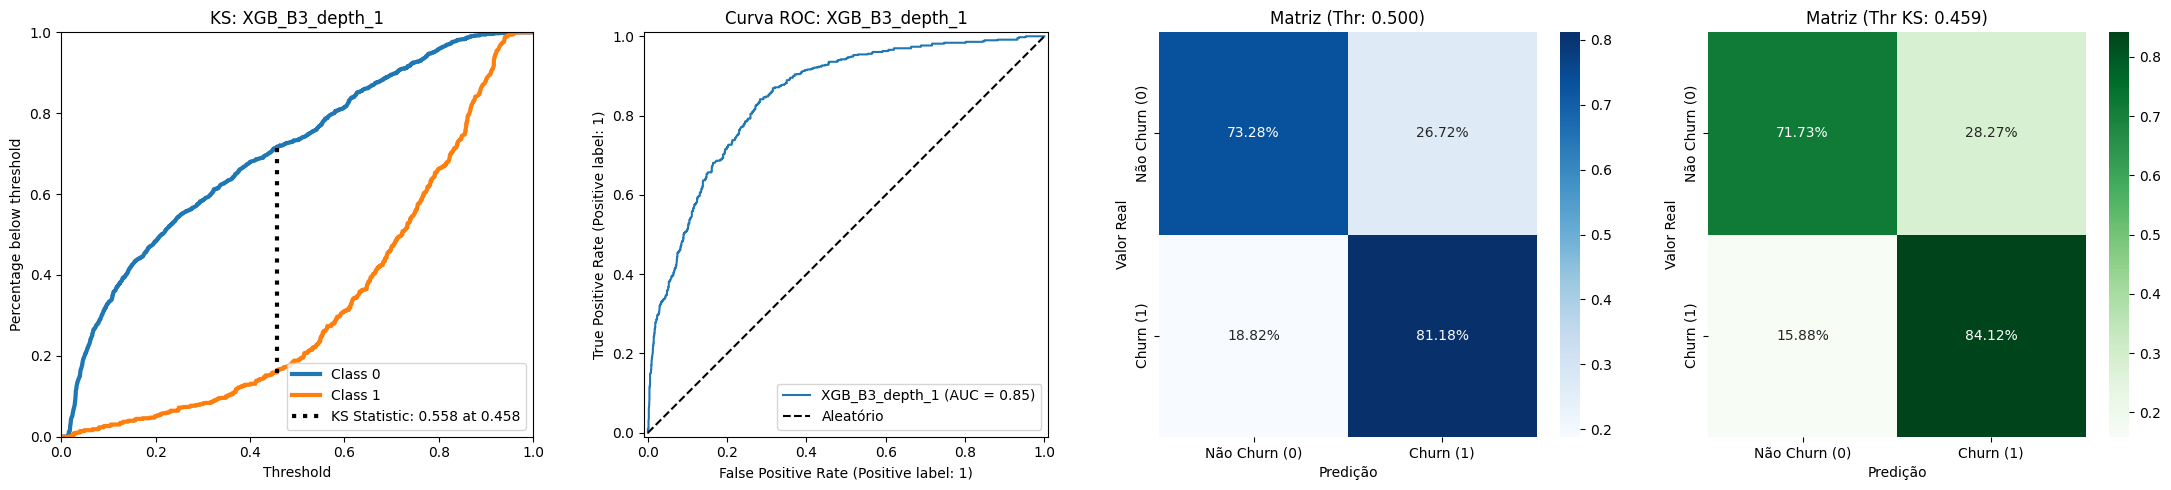

--- MÉTRICAS COM THRESHOLD PADRÃO (0.500) ---
KS: 0.5585 | AUROC: 0.8484 | MSE: 0.1572 | Log-Loss: 0.4830 | Acurácia: 0.7723
Precisão: 0.7523 | Recall: 0.8118 | F1-Score: 0.7809

               precision    recall  f1-score   support

Não Churn (0)       0.80      0.73      0.76      1291
    Churn (1)       0.75      0.81      0.78      1291

     accuracy                           0.77      2582
    macro avg       0.77      0.77      0.77      2582
 weighted avg       0.77      0.77      0.77      2582


--- MÉTRICAS COM THRESHOLD OTIMIZADO PELO KS (0.459) ---
KS: 0.5585 | AUROC: 0.8484 | Acurácia: 0.7792
Precisão: 0.7484 | Recall: 0.8412 | F1-Score: 0.7921

               precision    recall  f1-score   support

Não Churn (0)       0.82      0.72      0.76      1291
    Churn (1)       0.75      0.84      0.79      1291

     accuracy                           0.78      2582
    macro avg       0.78      0.78      0.78      2582
 weighted avg       0.78      0.78      0.78      258

,max_depth,val_ks,train_mse,val_mse,val_loss
0,1,0.5585,0.1520,0.1572,0.4830
1,2,0.5538,0.1500,0.1588,0.4875
2,3,0.5562,0.1444,0.1597,0.4902
3,4,0.5546,0.1431,0.1606,0.4922
4,5,0.5546,0.1371,0.1625,0.4969
5,6,0.5523,0.1344,0.1634,0.4987


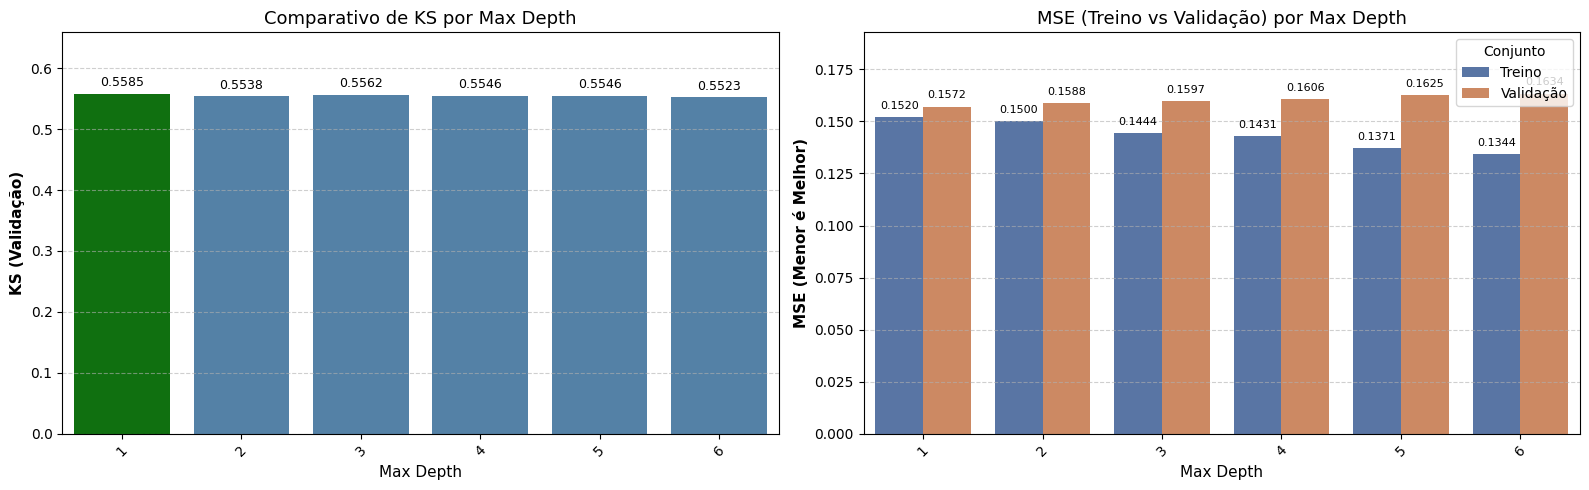

In [ ]:
print("Iniciando Bateria 3: max_depth...")
resultados_b3 = []
melhor_lr = vencedor_b2['learning_rate']

for d in [1, 2, 3, 4, 5, 6]:
    res = executar_experimento_xgb(
        name_experiment=f"XGB_B3_depth_{d}",
        learning_rate=melhor_lr, n_estimators=melhor_n_est, max_depth=d, min_child_weight=20,
        subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
        X_train=X_train_xgb, y_train=y_train_xgb, X_val=X_val_xgb, y_val=y_val_xgb
    )
    resultados_b3.append(res)

df_resultados_b3 = pd.DataFrame(resultados_b3)
df_resultados_b3.to_csv(os.path.join(caminho_logs_xgb, "bateria_3_max_depth.csv"), index=False)
vencedor_b3 = plotar_vencedor_xgb(resultados_b3, X_val_xgb, y_val_xgb)
plotar_evolucao_parametros(df_resultados_b3, 'max_depth')

### Bateria 4: Testando Peso Mínimo por Folha (`min_child_weight` - Anti-Overfitting do Oversampling)

Iniciando Bateria 4: min_child_weight...

------------------------------------------------------------------------------------------------------------------------
EXP XGB: XGB_B4_mcw_1 | LR: 0.1000 | Est: 300 | Depth: 1 | MinChildW: 1 | Sub: 0.80 | ColTree: 0.80 | L2: 1.00
Resultados: Val Loss: 0.4827 | KS: 0.5523 | AUC: 0.8481 | Train MSE: 0.1513 | Val MSE: 0.1575 | F1: 0.7821 | Tempo: 5.67s
Árvores mantidas (Early Stopping Externo): 205 / 300

------------------------------------------------------------------------------------------------------------------------
EXP XGB: XGB_B4_mcw_5 | LR: 0.1000 | Est: 300 | Depth: 1 | MinChildW: 5 | Sub: 0.80 | ColTree: 0.80 | L2: 1.00
Resultados: Val Loss: 0.4827 | KS: 0.5523 | AUC: 0.8483 | Train MSE: 0.1516 | Val MSE: 0.1575 | F1: 0.7826 | Tempo: 1.94s
Árvores mantidas (Early Stopping Externo): 193 / 300

------------------------------------------------------------------------------------------------------------------------
EXP XGB: XGB_B4_mcw_1

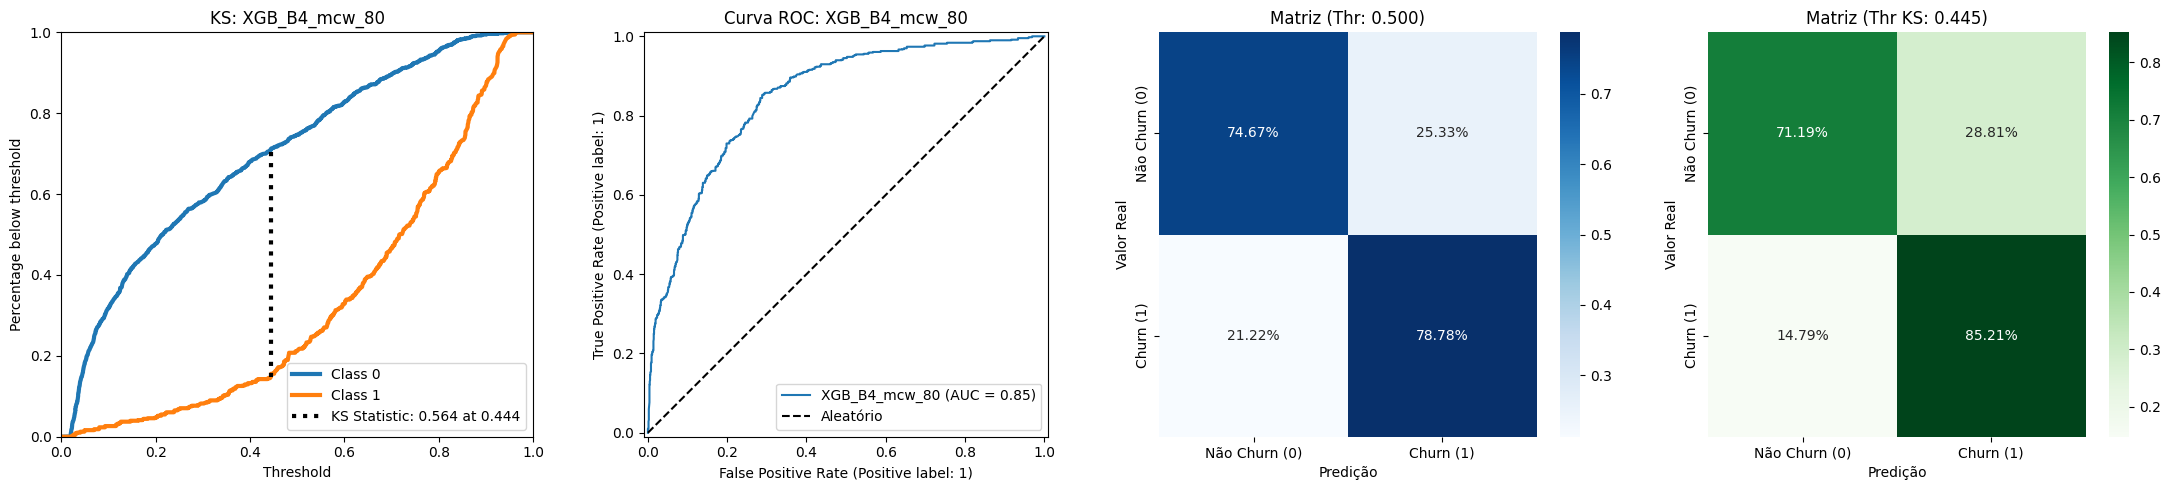

--- MÉTRICAS COM THRESHOLD PADRÃO (0.500) ---
KS: 0.5639 | AUROC: 0.8476 | MSE: 0.1578 | Log-Loss: 0.4841 | Acurácia: 0.7672
Precisão: 0.7567 | Recall: 0.7878 | F1-Score: 0.7719

               precision    recall  f1-score   support

Não Churn (0)       0.78      0.75      0.76      1291
    Churn (1)       0.76      0.79      0.77      1291

     accuracy                           0.77      2582
    macro avg       0.77      0.77      0.77      2582
 weighted avg       0.77      0.77      0.77      2582


--- MÉTRICAS COM THRESHOLD OTIMIZADO PELO KS (0.445) ---
KS: 0.5639 | AUROC: 0.8476 | Acurácia: 0.7820
Precisão: 0.7473 | Recall: 0.8521 | F1-Score: 0.7962

               precision    recall  f1-score   support

Não Churn (0)       0.83      0.71      0.77      1291
    Churn (1)       0.75      0.85      0.80      1291

     accuracy                           0.78      2582
    macro avg       0.79      0.78      0.78      2582
 weighted avg       0.79      0.78      0.78      258

,min_child_weight,val_ks,train_mse,val_mse,val_loss
0,1,0.5523,0.1513,0.1575,0.4827
1,5,0.5523,0.1516,0.1575,0.4827
2,15,0.5538,0.1518,0.1570,0.4822
3,30,0.5531,0.1523,0.1576,0.4847
4,50,0.5562,0.1524,0.1575,0.4843
5,80,0.5639,0.1525,0.1578,0.4841


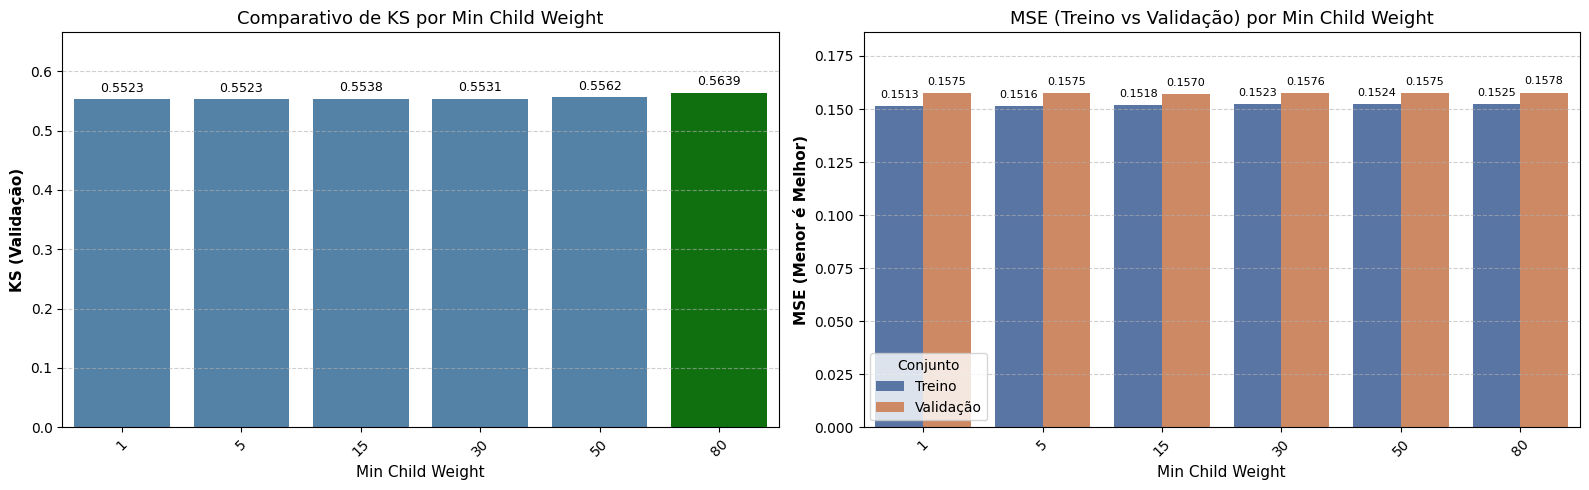

In [ ]:
print("Iniciando Bateria 4: min_child_weight...")
resultados_b4 = []
melhor_depth = vencedor_b3['max_depth']

for mcw in [1, 5, 15, 30, 50, 80]:
    res = executar_experimento_xgb(
        name_experiment=f"XGB_B4_mcw_{mcw}",
        learning_rate=melhor_lr, n_estimators=melhor_n_est, max_depth=melhor_depth, min_child_weight=mcw,
        subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
        X_train=X_train_xgb, y_train=y_train_xgb, X_val=X_val_xgb, y_val=y_val_xgb
    )
    resultados_b4.append(res)

df_resultados_b4 = pd.DataFrame(resultados_b4)
df_resultados_b4.to_csv(os.path.join(caminho_logs_xgb, "bateria_4_min_child_weight.csv"), index=False)
vencedor_b4 = plotar_vencedor_xgb(resultados_b4, X_val_xgb, y_val_xgb)
plotar_evolucao_parametros(df_resultados_b4, 'min_child_weight')

### Bateria 5: Testando Subamostragem de Linhas (`subsample`)

Iniciando Bateria 5: subsample...

------------------------------------------------------------------------------------------------------------------------
EXP XGB: XGB_B5_sub_0.5 | LR: 0.1000 | Est: 300 | Depth: 1 | MinChildW: 80 | Sub: 0.50 | ColTree: 0.80 | L2: 1.00
Resultados: Val Loss: 0.4869 | KS: 0.5430 | AUC: 0.8454 | Train MSE: 0.1538 | Val MSE: 0.1593 | F1: 0.7645 | Tempo: 0.80s
Árvores mantidas (Early Stopping Externo): 146 / 300

------------------------------------------------------------------------------------------------------------------------
EXP XGB: XGB_B5_sub_0.6 | LR: 0.1000 | Est: 300 | Depth: 1 | MinChildW: 80 | Sub: 0.60 | ColTree: 0.80 | L2: 1.00
Resultados: Val Loss: 0.4841 | KS: 0.5608 | AUC: 0.8477 | Train MSE: 0.1528 | Val MSE: 0.1581 | F1: 0.7678 | Tempo: 0.42s
Árvores mantidas (Early Stopping Externo): 175 / 300

------------------------------------------------------------------------------------------------------------------------
EXP XGB: XGB_B5_sub_0.

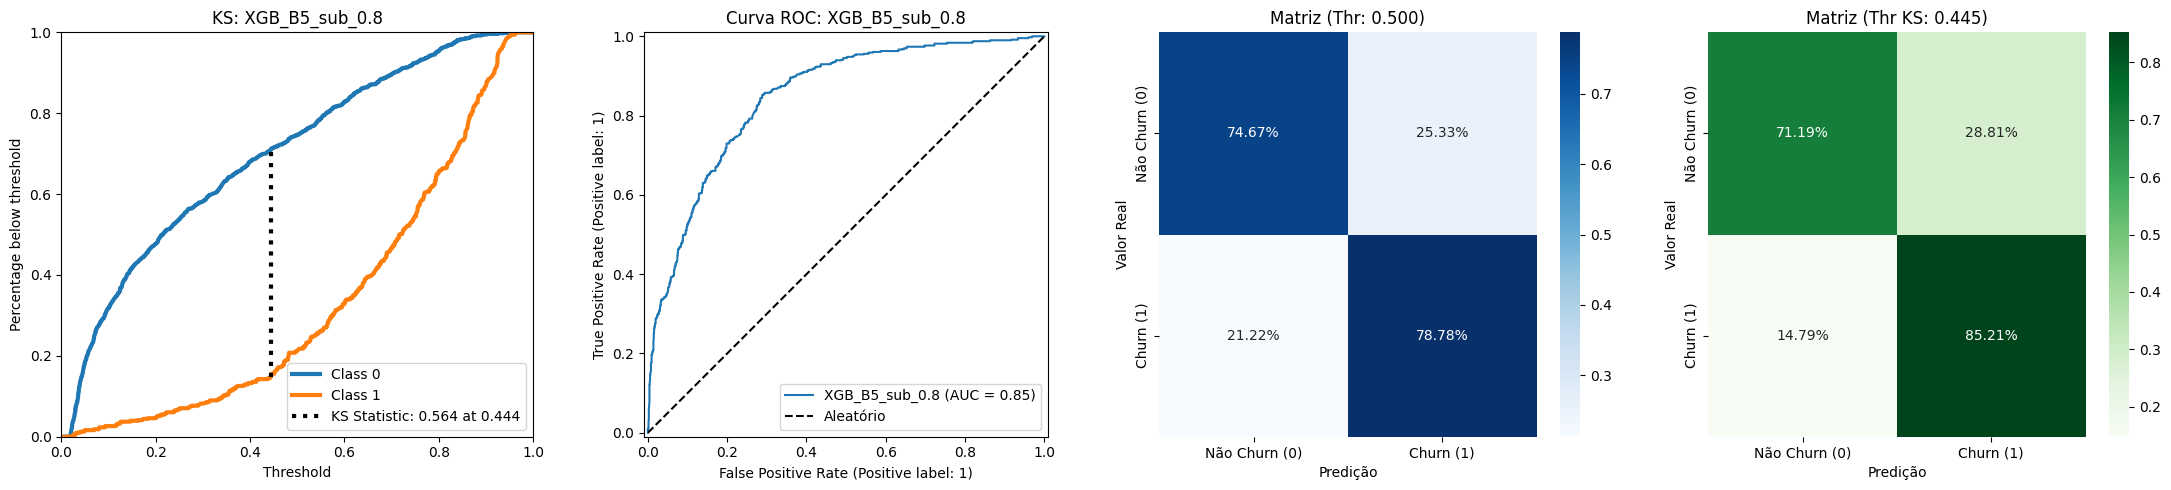

--- MÉTRICAS COM THRESHOLD PADRÃO (0.500) ---
KS: 0.5639 | AUROC: 0.8476 | MSE: 0.1578 | Log-Loss: 0.4841 | Acurácia: 0.7672
Precisão: 0.7567 | Recall: 0.7878 | F1-Score: 0.7719

               precision    recall  f1-score   support

Não Churn (0)       0.78      0.75      0.76      1291
    Churn (1)       0.76      0.79      0.77      1291

     accuracy                           0.77      2582
    macro avg       0.77      0.77      0.77      2582
 weighted avg       0.77      0.77      0.77      2582


--- MÉTRICAS COM THRESHOLD OTIMIZADO PELO KS (0.445) ---
KS: 0.5639 | AUROC: 0.8476 | Acurácia: 0.7820
Precisão: 0.7473 | Recall: 0.8521 | F1-Score: 0.7962

               precision    recall  f1-score   support

Não Churn (0)       0.83      0.71      0.77      1291
    Churn (1)       0.75      0.85      0.80      1291

     accuracy                           0.78      2582
    macro avg       0.79      0.78      0.78      2582
 weighted avg       0.79      0.78      0.78      258

,subsample,val_ks,train_mse,val_mse,val_loss
0,0.5,0.5430,0.1538,0.1593,0.4869
1,0.6,0.5608,0.1528,0.1581,0.4841
2,0.7,0.5600,0.1523,0.1578,0.4839
3,0.8,0.5639,0.1525,0.1578,0.4841
4,0.9,0.5531,0.1528,0.1579,0.4845
5,1.0,0.5631,0.1522,0.1576,0.4840


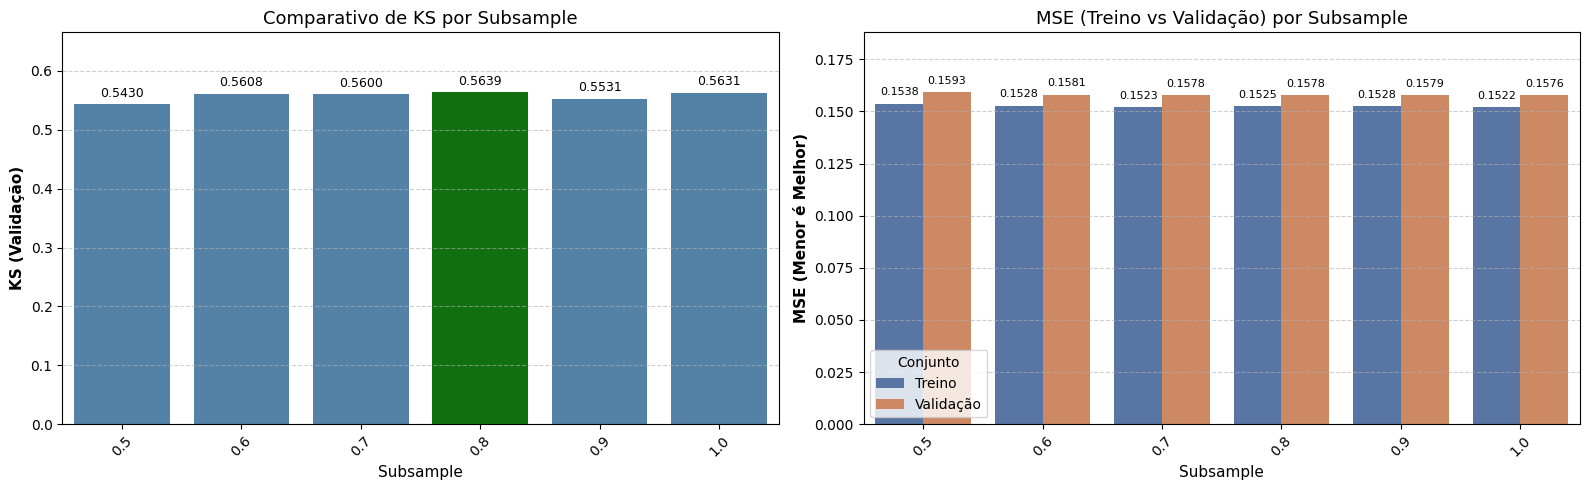

In [ ]:
print("Iniciando Bateria 5: subsample...")
resultados_b5 = []
melhor_mcw = vencedor_b4['min_child_weight']

for sub in [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]:
    res = executar_experimento_xgb(
        name_experiment=f"XGB_B5_sub_{sub}",
        learning_rate=melhor_lr, n_estimators=melhor_n_est, max_depth=melhor_depth, min_child_weight=melhor_mcw,
        subsample=sub, colsample_bytree=0.8, reg_lambda=1.0,
        X_train=X_train_xgb, y_train=y_train_xgb, X_val=X_val_xgb, y_val=y_val_xgb
    )
    resultados_b5.append(res)

df_resultados_b5 = pd.DataFrame(resultados_b5)
df_resultados_b5.to_csv(os.path.join(caminho_logs_xgb, "bateria_5_subsample.csv"), index=False)
vencedor_b5 = plotar_vencedor_xgb(resultados_b5, X_val_xgb, y_val_xgb)
plotar_evolucao_parametros(df_resultados_b5, 'subsample')

### Bateria 6: Testando Subamostragem de Colunas (`colsample_bytree`)

Iniciando Bateria 6: colsample_bytree...

------------------------------------------------------------------------------------------------------------------------
EXP XGB: XGB_B6_col_0.4 | LR: 0.1000 | Est: 300 | Depth: 1 | MinChildW: 80 | Sub: 0.80 | ColTree: 0.40 | L2: 1.00
Resultados: Val Loss: 0.4851 | KS: 0.5515 | AUC: 0.8467 | Train MSE: 0.1529 | Val MSE: 0.1581 | F1: 0.7746 | Tempo: 0.40s
Árvores mantidas (Early Stopping Externo): 167 / 300

------------------------------------------------------------------------------------------------------------------------
EXP XGB: XGB_B6_col_0.5 | LR: 0.1000 | Est: 300 | Depth: 1 | MinChildW: 80 | Sub: 0.80 | ColTree: 0.50 | L2: 1.00
Resultados: Val Loss: 0.4841 | KS: 0.5624 | AUC: 0.8476 | Train MSE: 0.1525 | Val MSE: 0.1577 | F1: 0.7736 | Tempo: 0.48s
Árvores mantidas (Early Stopping Externo): 193 / 300

------------------------------------------------------------------------------------------------------------------------
EXP XGB: XGB_B6

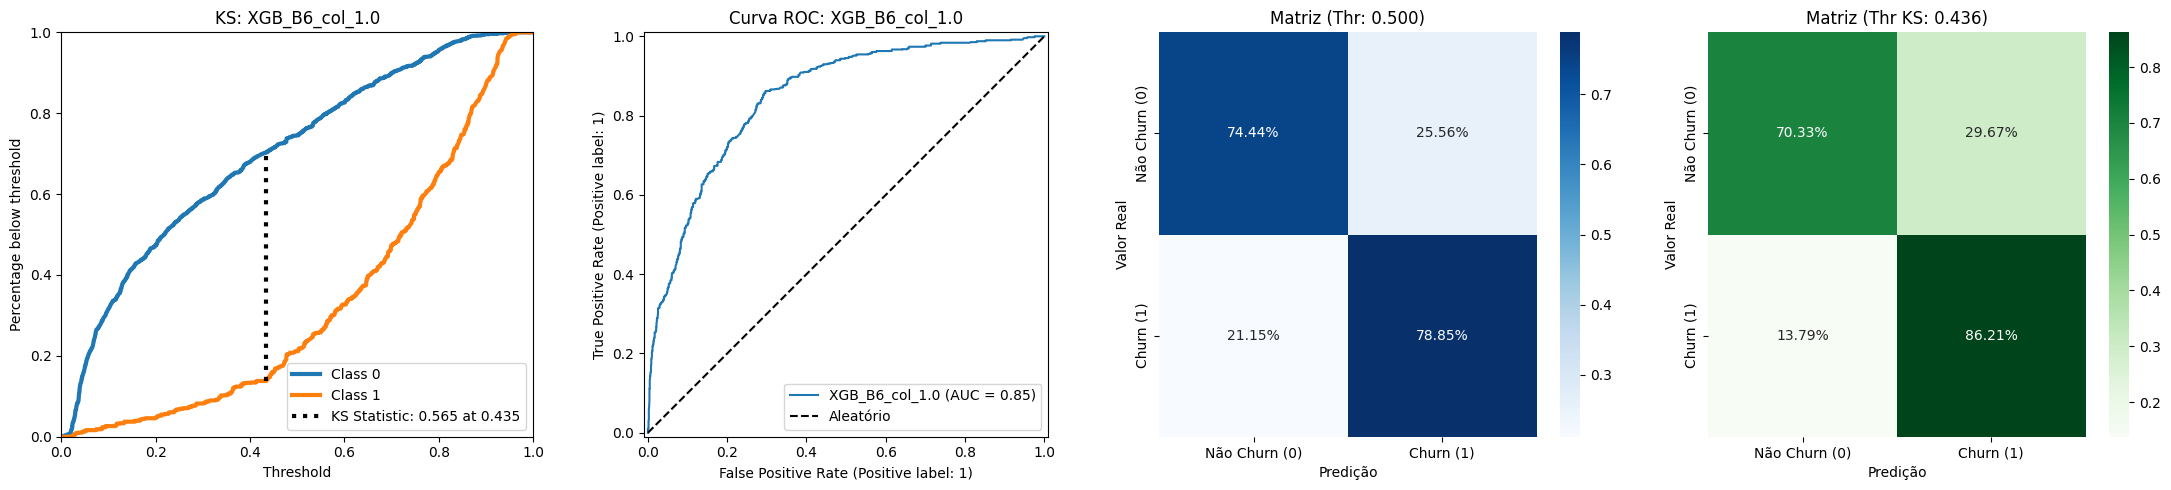

--- MÉTRICAS COM THRESHOLD PADRÃO (0.500) ---
KS: 0.5655 | AUROC: 0.8478 | MSE: 0.1576 | Log-Loss: 0.4836 | Acurácia: 0.7665
Precisão: 0.7552 | Recall: 0.7885 | F1-Score: 0.7715

               precision    recall  f1-score   support

Não Churn (0)       0.78      0.74      0.76      1291
    Churn (1)       0.76      0.79      0.77      1291

     accuracy                           0.77      2582
    macro avg       0.77      0.77      0.77      2582
 weighted avg       0.77      0.77      0.77      2582


--- MÉTRICAS COM THRESHOLD OTIMIZADO PELO KS (0.436) ---
KS: 0.5655 | AUROC: 0.8478 | Acurácia: 0.7827
Precisão: 0.7440 | Recall: 0.8621 | F1-Score: 0.7987

               precision    recall  f1-score   support

Não Churn (0)       0.84      0.70      0.76      1291
    Churn (1)       0.74      0.86      0.80      1291

     accuracy                           0.78      2582
    macro avg       0.79      0.78      0.78      2582
 weighted avg       0.79      0.78      0.78      258

,colsample_bytree,val_ks,train_mse,val_mse,val_loss
0,0.4,0.5515,0.1529,0.1581,0.4851
1,0.5,0.5624,0.1525,0.1577,0.4841
2,0.6,0.5585,0.1525,0.1578,0.4845
3,0.7,0.5624,0.1525,0.1578,0.4843
4,0.8,0.5639,0.1525,0.1578,0.4841
5,0.9,0.5608,0.1526,0.1577,0.4840
6,1.0,0.5655,0.1525,0.1576,0.4836


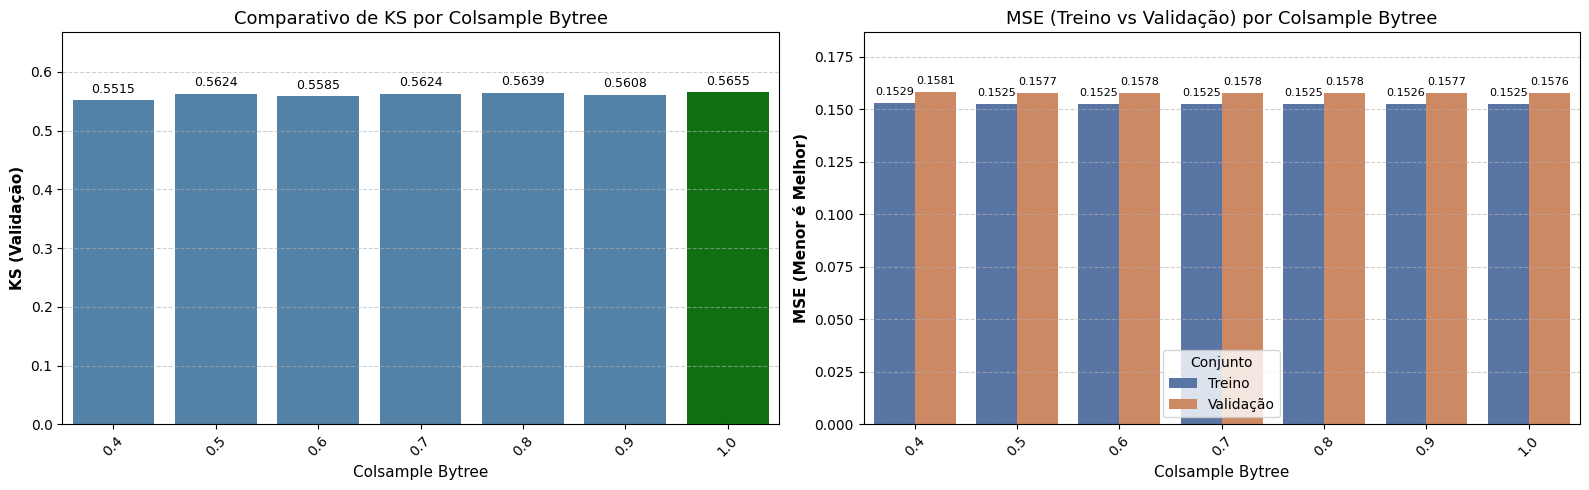

In [ ]:
print("Iniciando Bateria 6: colsample_bytree...")
resultados_b6 = []
melhor_sub = vencedor_b5['subsample']

for col in [0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]:
    res = executar_experimento_xgb(
        name_experiment=f"XGB_B6_col_{col}",
        learning_rate=melhor_lr, n_estimators=melhor_n_est, max_depth=melhor_depth, min_child_weight=melhor_mcw,
        subsample=melhor_sub, colsample_bytree=col, reg_lambda=1.0,
        X_train=X_train_xgb, y_train=y_train_xgb, X_val=X_val_xgb, y_val=y_val_xgb
    )
    resultados_b6.append(res)

df_resultados_b6 = pd.DataFrame(resultados_b6)
df_resultados_b6.to_csv(os.path.join(caminho_logs_xgb, "bateria_6_colsample_bytree.csv"), index=False)
vencedor_b6 = plotar_vencedor_xgb(resultados_b6, X_val_xgb, y_val_xgb)
plotar_evolucao_parametros(df_resultados_b6, 'colsample_bytree')

### Bateria 7: Testando Regularização L2 nas Folhas (`reg_lambda`)

Iniciando Bateria 7: reg_lambda...

------------------------------------------------------------------------------------------------------------------------
EXP XGB: XGB_B7_l2_0.1 | LR: 0.1000 | Est: 300 | Depth: 1 | MinChildW: 80 | Sub: 0.80 | ColTree: 1.00 | L2: 0.10
Resultados: Val Loss: 0.4832 | KS: 0.5670 | AUC: 0.8481 | Train MSE: 0.1522 | Val MSE: 0.1574 | F1: 0.7736 | Tempo: 0.82s
Árvores mantidas (Early Stopping Externo): 217 / 300

------------------------------------------------------------------------------------------------------------------------
EXP XGB: XGB_B7_l2_1.0 | LR: 0.1000 | Est: 300 | Depth: 1 | MinChildW: 80 | Sub: 0.80 | ColTree: 1.00 | L2: 1.00
Resultados: Val Loss: 0.4836 | KS: 0.5655 | AUC: 0.8478 | Train MSE: 0.1525 | Val MSE: 0.1576 | F1: 0.7715 | Tempo: 1.70s
Árvores mantidas (Early Stopping Externo): 188 / 300

------------------------------------------------------------------------------------------------------------------------
EXP XGB: XGB_B7_l2_5.0 

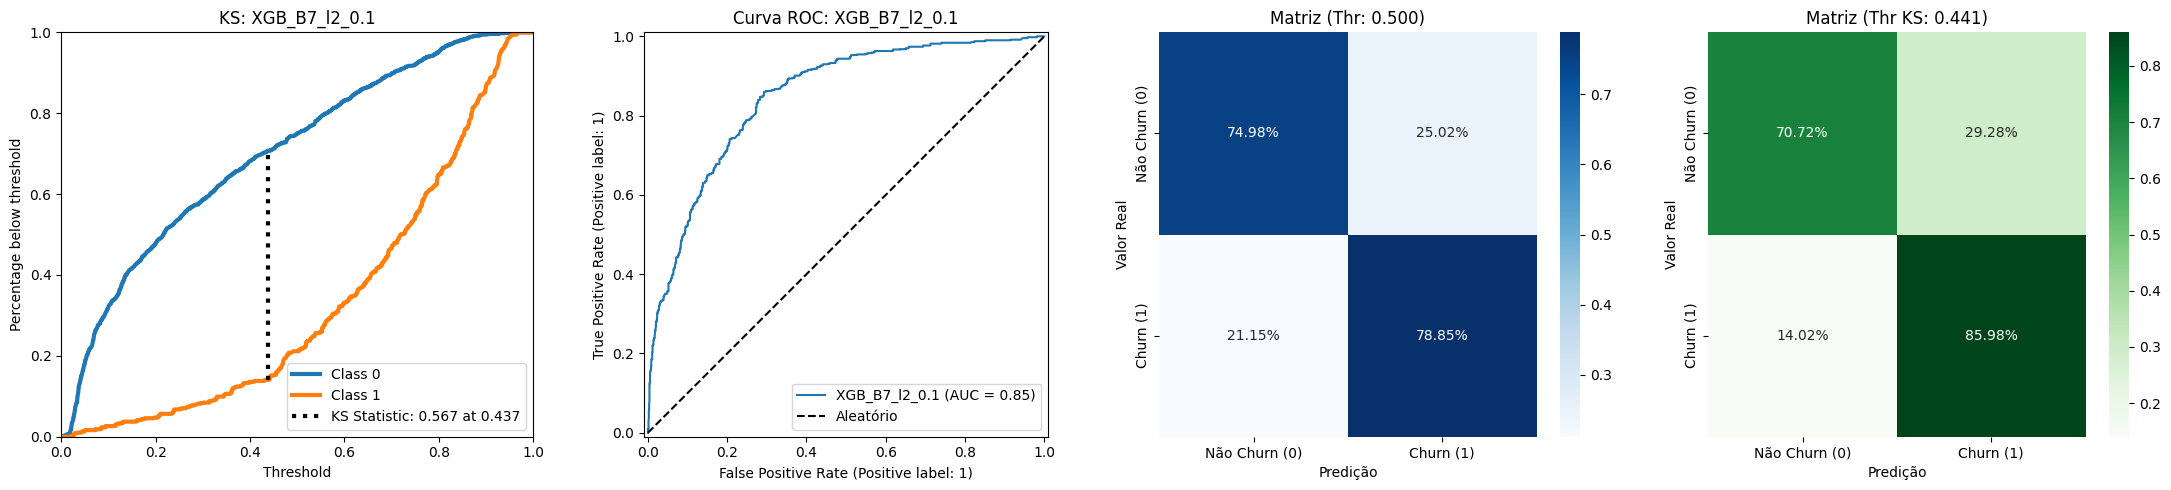

--- MÉTRICAS COM THRESHOLD PADRÃO (0.500) ---
KS: 0.5670 | AUROC: 0.8481 | MSE: 0.1574 | Log-Loss: 0.4832 | Acurácia: 0.7692
Precisão: 0.7591 | Recall: 0.7885 | F1-Score: 0.7736

               precision    recall  f1-score   support

Não Churn (0)       0.78      0.75      0.76      1291
    Churn (1)       0.76      0.79      0.77      1291

     accuracy                           0.77      2582
    macro avg       0.77      0.77      0.77      2582
 weighted avg       0.77      0.77      0.77      2582


--- MÉTRICAS COM THRESHOLD OTIMIZADO PELO KS (0.441) ---
KS: 0.5670 | AUROC: 0.8481 | Acurácia: 0.7835
Precisão: 0.7460 | Recall: 0.8598 | F1-Score: 0.7988

               precision    recall  f1-score   support

Não Churn (0)       0.83      0.71      0.77      1291
    Churn (1)       0.75      0.86      0.80      1291

     accuracy                           0.78      2582
    macro avg       0.79      0.78      0.78      2582
 weighted avg       0.79      0.78      0.78      258

,reg_lambda,val_ks,train_mse,val_mse,val_loss
0,0.1,0.5670,0.1522,0.1574,0.4832
1,1.0,0.5655,0.1525,0.1576,0.4836
2,5.0,0.5639,0.1526,0.1575,0.4835
3,10.0,0.5616,0.1526,0.1577,0.4839
4,25.0,0.5585,0.1528,0.1576,0.4834
5,50.0,0.5546,0.1530,0.1578,0.4837


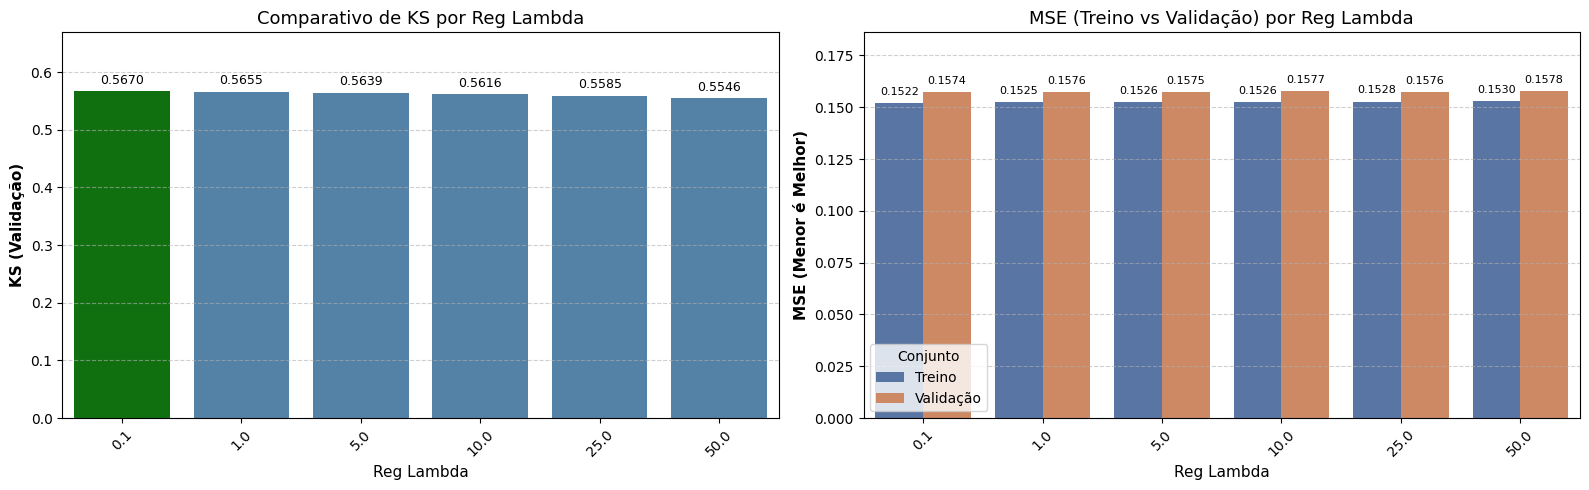

In [ ]:
print("Iniciando Bateria 7: reg_lambda...")
resultados_b7 = []
melhor_col = vencedor_b6['colsample_bytree']

for l2 in [0.1, 1.0, 5.0, 10.0, 25.0, 50.0]:
    res = executar_experimento_xgb(
        name_experiment=f"XGB_B7_l2_{l2}",
        learning_rate=melhor_lr, n_estimators=melhor_n_est, max_depth=melhor_depth, min_child_weight=melhor_mcw,
        subsample=melhor_sub, colsample_bytree=melhor_col, reg_lambda=l2,
        X_train=X_train_xgb, y_train=y_train_xgb, X_val=X_val_xgb, y_val=y_val_xgb
    )
    resultados_b7.append(res)

df_resultados_b7 = pd.DataFrame(resultados_b7)
df_resultados_b7.to_csv(os.path.join(caminho_logs_xgb, "bateria_7_reg_lambda.csv"), index=False)
vencedor_b7 = plotar_vencedor_xgb(resultados_b7, X_val_xgb, y_val_xgb)
plotar_evolucao_parametros(df_resultados_b7, 'reg_lambda')

## Optuna: Otimização Global de Hiperparâmetros (Baseline Original)

###Objective Function

In [ ]:
import optuna
from optuna.samplers import TPESampler

N_TRIALS_OPTUNA = 100 # Alinhado estritamente ao roteiro e aos demais modelos (100 trials)

def sugerir_hiperparametros_xgb(trial):
    """Espaço de busca calibrado para alta generalização no Teste (evitando memorizar cópias do oversampling)."""
    return {
        'learning_rate': trial.suggest_float('learning_rate', 0.005, 0.12, log=True),
        'n_estimators': trial.suggest_int('n_estimators', 200, 3000),
        'max_depth': trial.suggest_int('max_depth', 1, 4),
        'min_child_weight': trial.suggest_int('min_child_weight', 10, 80),
        'subsample': trial.suggest_float('subsample', 0.5, 0.95),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.4, 1.0),
        'colsample_bylevel': trial.suggest_float('colsample_bylevel', 0.5, 1.0),
        'gamma': trial.suggest_float('gamma', 0.0, 5.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1.0, 50.0, log=True)
    }

def objective_xgb(trial):
    params = sugerir_hiperparametros_xgb(trial)
    nome_trial = f"Optuna_Trial_{trial.number}"
    resultado = executar_experimento_xgb(
        name_experiment=nome_trial,
        **params,
        X_train=X_train_xgb,
        y_train=y_train_xgb,
        X_val=X_val_xgb,
        y_val=y_val_xgb
    )
    return resultado['val_ks']

###Run and Save

In [ ]:
caminho_banco_optuna = f"sqlite:///{caminho_logs_xgb}/optuna_xgb_baseline.db"
RECOMECAR_DO_ZERO = False # False permite retomar automaticamente caso a sessão do Colab caia

if RECOMECAR_DO_ZERO:
    try:
        optuna.delete_study(study_name="Otimizacao_XGB", storage=caminho_banco_optuna)
        print("Estudo anterior apagado. Começando do zero!")
    except KeyError:
        pass

sampler = TPESampler(seed=42)
study_xgb = optuna.create_study(
    study_name="Otimizacao_XGB",
    direction="maximize",
    storage=caminho_banco_optuna,
    sampler=sampler,
    load_if_exists=True
)

n_trials_restantes = max(0, N_TRIALS_OPTUNA - len(study_xgb.trials))
print(f"Iniciando/Retomando Optuna XGB Base (concluídos: {len(study_xgb.trials)} | restantes: {n_trials_restantes})...")
if n_trials_restantes > 0:
    study_xgb.optimize(objective_xgb, n_trials=n_trials_restantes)

print("\n=== MELHOR MODELO ENCONTRADO PELO OPTUNA (BASE) ===")
print(f"Melhor KS: {study_xgb.best_value:.4f}")
for k, v in study_xgb.best_params.items():
    print(f"    {k}: {v}")

[I 2026-11-26 01:34:33,413] A new study created in RDB with name: Otimizacao_XGB


Iniciando/Retomando Optuna XGB Base (concluídos: 0 | restantes: 100)...

------------------------------------------------------------------------------------------------------------------------
EXP XGB: Optuna_Trial_0 | LR: 0.0164 | Est: 2862 | Depth: 3 | MinChildW: 52 | Sub: 0.57 | ColTree: 0.49 | L2: 15.96


[I 2026-11-26 01:34:35,039] Trial 0 finished with value: 0.5530596436870643 and parameters: {'learning_rate': 0.016440479761182902, 'n_estimators': 2862, 'max_depth': 3, 'min_child_weight': 52, 'subsample': 0.5702083881990965, 'colsample_bytree': 0.49359671220172163, 'colsample_bylevel': 0.5290418060840998, 'gamma': 4.330880728874676, 'reg_alpha': 0.2537815508265665, 'reg_lambda': 15.958573588141263}. Best is trial 0 with value: 0.5530596436870643.


Resultados: Val Loss: 0.4852 | KS: 0.5531 | AUC: 0.8473 | Train MSE: 0.1507 | Val MSE: 0.1584 | F1: 0.7774 | Tempo: 1.23s
Árvores mantidas (Early Stopping Externo): 571 / 2862

------------------------------------------------------------------------------------------------------------------------
EXP XGB: Optuna_Trial_1 | LR: 0.0053 | Est: 2916 | Depth: 4 | MinChildW: 25 | Sub: 0.58 | ColTree: 0.51 | L2: 3.12


[I 2026-11-26 01:34:37,616] Trial 1 finished with value: 0.5561580170410535 and parameters: {'learning_rate': 0.005338029318481386, 'n_estimators': 2916, 'max_depth': 4, 'min_child_weight': 25, 'subsample': 0.5818212352431953, 'colsample_bytree': 0.5100427059120604, 'colsample_bylevel': 0.6521211214797689, 'gamma': 2.6237821581611893, 'reg_alpha': 0.05342937261279776, 'reg_lambda': 3.124565071260871}. Best is trial 1 with value: 0.5561580170410535.


Resultados: Val Loss: 0.4873 | KS: 0.5562 | AUC: 0.8462 | Train MSE: 0.1452 | Val MSE: 0.1590 | F1: 0.7762 | Tempo: 2.21s
Árvores mantidas (Early Stopping Externo): 909 / 2916

------------------------------------------------------------------------------------------------------------------------
EXP XGB: Optuna_Trial_2 | LR: 0.0350 | Est: 590 | Depth: 2 | MinChildW: 36 | Sub: 0.71 | ColTree: 0.87 | L2: 1.20


... (192 outputs left out)

[I 2026-11-26 01:36:43,914] Trial 98 finished with value: 0.5530596436870643 and parameters: {'learning_rate': 0.03592656204736055, 'n_estimators': 1295, 'max_depth': 2, 'min_child_weight': 37, 'subsample': 0.7567332656834567, 'colsample_bytree': 0.988637934027518, 'colsample_bylevel': 0.6375481087020833, 'gamma': 1.5805001050255036, 'reg_alpha': 0.18168991441068422, 'reg_lambda': 2.2167031658410523}. Best is trial 45 with value: 0.5677769171185127.


Resultados: Val Loss: 0.4870 | KS: 0.5531 | AUC: 0.8476 | Train MSE: 0.1500 | Val MSE: 0.1583 | F1: 0.7792 | Tempo: 0.54s
Árvores mantidas (Early Stopping Externo): 195 / 1295

------------------------------------------------------------------------------------------------------------------------
EXP XGB: Optuna_Trial_99 | LR: 0.0404 | Est: 652 | Depth: 2 | MinChildW: 41 | Sub: 0.73 | ColTree: 1.00 | L2: 1.94


[I 2026-11-26 01:36:44,961] Trial 99 finished with value: 0.557707203718048 and parameters: {'learning_rate': 0.04035617052635617, 'n_estimators': 652, 'max_depth': 2, 'min_child_weight': 41, 'subsample': 0.7297631068771068, 'colsample_bytree': 0.9976451315294393, 'colsample_bylevel': 0.575023134057553, 'gamma': 1.3754858520509934, 'reg_alpha': 0.8281142095028519, 'reg_lambda': 1.9441098430215298}. Best is trial 45 with value: 0.5677769171185127.


Resultados: Val Loss: 0.4874 | KS: 0.5577 | AUC: 0.8470 | Train MSE: 0.1496 | Val MSE: 0.1584 | F1: 0.7710 | Tempo: 0.53s
Árvores mantidas (Early Stopping Externo): 192 / 652

=== MELHOR MODELO ENCONTRADO PELO OPTUNA (BASE) ===
Melhor KS: 0.5678
    learning_rate: 0.04726191536982415
    n_estimators: 645
    max_depth: 2
    min_child_weight: 44
    subsample: 0.7612163873113824
    colsample_bytree: 0.939517393728034
    colsample_bylevel: 0.5482308234883693
    gamma: 1.200376815672707
    reg_alpha: 0.1188189311876597
    reg_lambda: 2.3815089799539413


###Evaluate Best Model


VENCEDOR DA BATERIA: Optuna_Trial_45 (KS Máximo: 0.5678)


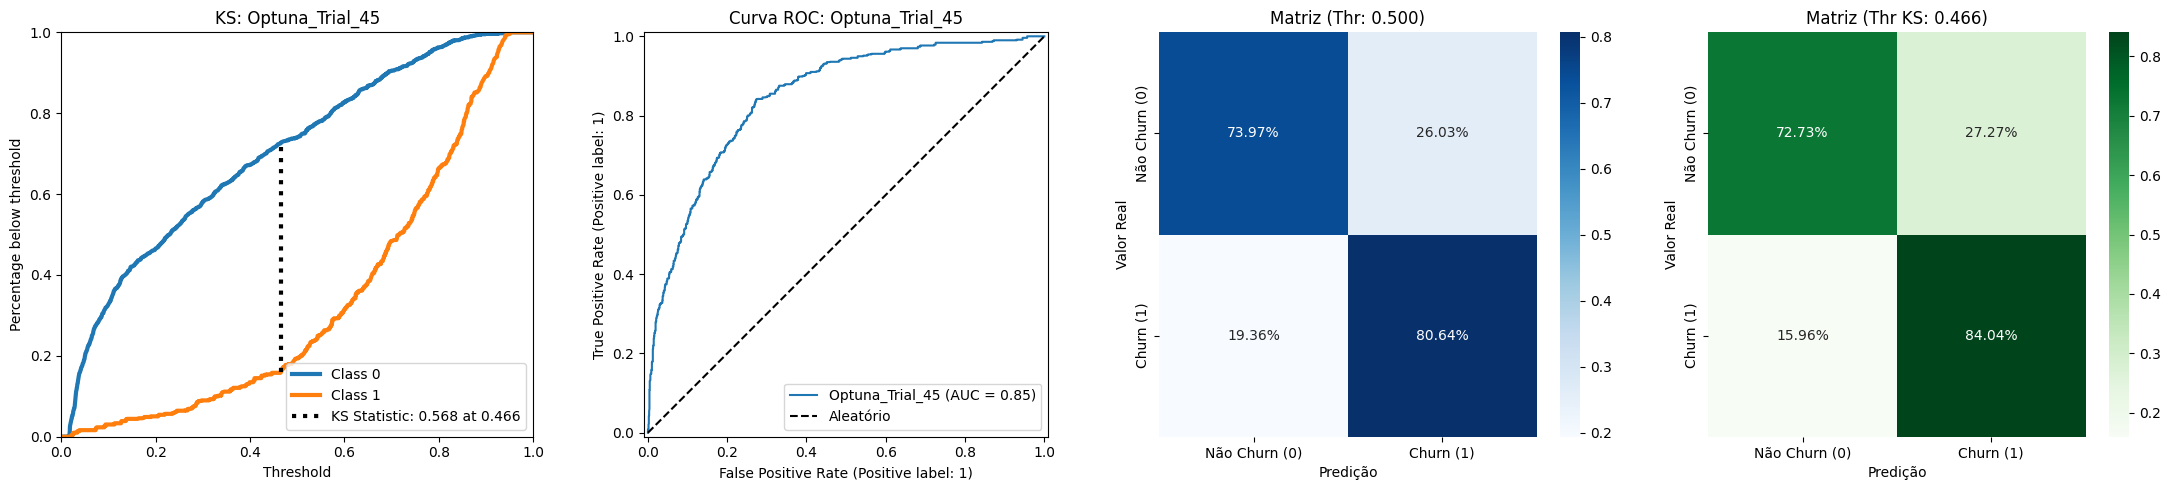

--- MÉTRICAS COM THRESHOLD PADRÃO (0.500) ---
KS: 0.5678 | AUROC: 0.8485 | MSE: 0.1577 | Log-Loss: 0.4857 | Acurácia: 0.7730
Precisão: 0.7560 | Recall: 0.8064 | F1-Score: 0.7804

               precision    recall  f1-score   support

Não Churn (0)       0.79      0.74      0.77      1291
    Churn (1)       0.76      0.81      0.78      1291

     accuracy                           0.77      2582
    macro avg       0.77      0.77      0.77      2582
 weighted avg       0.77      0.77      0.77      2582


--- MÉTRICAS COM THRESHOLD OTIMIZADO PELO KS (0.466) ---
KS: 0.5678 | AUROC: 0.8485 | Acurácia: 0.7839
Precisão: 0.7550 | Recall: 0.8404 | F1-Score: 0.7955

               precision    recall  f1-score   support

Não Churn (0)       0.82      0.73      0.77      1291
    Churn (1)       0.76      0.84      0.80      1291

     accuracy                           0.78      2582
    macro avg       0.79      0.78      0.78      2582
 weighted avg       0.79      0.78      0.78      258

In [ ]:
melhor_trial_base = study_xgb.best_trial
resultado_campeao_base = {
    'nome': f"Optuna_Trial_{melhor_trial_base.number}",
    'val_ks': melhor_trial_base.value,
    **melhor_trial_base.params
}
_ = plotar_vencedor_xgb([resultado_campeao_base], X_val_xgb, y_val_xgb)

# Feature Engineering para Churn de Telecom

##Função de Plotagem de Comparação

In [ ]:
def plot_feature_engineering_comparison_xgb(name_fe, ks_man_base, ks_man_fe, ks_optuna_base, ks_optuna_fe):
    labels = ['Manual (B7) - Sem FE', f'Manual (B7) - Com {name_fe}',
              'Optuna - Sem FE', f'Optuna - Com {name_fe}']
    ks_values = [ks_man_base, ks_man_fe, ks_optuna_base, ks_optuna_fe]
    cores = ['lightsteelblue', 'royalblue', 'lightgreen', 'forestgreen']

    fig, ax = plt.subplots(figsize=(10, 6))
    barras = ax.bar(labels, ks_values, color=cores)
    for bar in barras:
        height = bar.get_height()
        ax.annotate(f'{height:.4f}',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 4), textcoords="offset points",
                    ha='center', va='bottom', fontsize=11, fontweight='bold')

    ax.set_ylim(min(ks_values) - 0.015, max(ks_values) + 0.02)
    ax.set_ylabel('Estatística KS', fontsize=12)
    ax.set_title(f'Impacto da Feature no XGBoost: {name_fe}', fontsize=14, pad=15)
    plt.xticks(rotation=15, ha='right')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

### Setup para os Testes de Feature Engineering (Ablation Study)

In [ ]:
# 1. Carregando Hiperparâmetros do Campeão Manual (Bateria 7)
caminho_csv_b7 = os.path.join(caminho_logs_xgb, "bateria_7_reg_lambda.csv")
df_b7 = pd.read_csv(caminho_csv_b7)
vencedor_b7_dict = df_b7.loc[df_b7['val_ks'].idxmax()].to_dict()
ks_b7_base = vencedor_b7_dict['val_ks']
params_manual_campeao = {
    'learning_rate': float(vencedor_b7_dict['learning_rate']),
    'n_estimators': int(vencedor_b7_dict['n_estimators']),
    'max_depth': int(vencedor_b7_dict['max_depth']),
    'min_child_weight': int(vencedor_b7_dict['min_child_weight']),
    'subsample': float(vencedor_b7_dict['subsample']),
    'colsample_bytree': float(vencedor_b7_dict['colsample_bytree']),
    'colsample_bylevel': float(vencedor_b7_dict.get('colsample_bylevel', 1.0)),
    'gamma': float(vencedor_b7_dict.get('gamma', 0.0)),
    'reg_alpha': float(vencedor_b7_dict.get('reg_alpha', 0.0)),
    'reg_lambda': float(vencedor_b7_dict['reg_lambda'])
}
print(f"Campeão Manual ({vencedor_b7_dict['nome']}) carregado. KS: {ks_b7_base:.4f}")

# 2. Carregando Hiperparâmetros do Campeão Optuna Base
caminho_banco_optuna = f"sqlite:///{caminho_logs_xgb}/optuna_xgb_baseline.db"
study_xgb_loaded = optuna.load_study(study_name="Otimizacao_XGB", storage=caminho_banco_optuna)
best_trial_xgb = study_xgb_loaded.best_trial
ks_optuna_base_xgb = best_trial_xgb.value
print(f"Campeão Optuna Base (Trial {best_trial_xgb.number}) carregado. KS: {ks_optuna_base_xgb:.4f}")

# 3. Função unificada para rodar Optuna nas FEs
def rodar_optuna_e_avaliar_xgb(nome_estudo, X_train, y_train, X_val, y_val, prefixo_trial):
    caminho_banco = f"sqlite:///{caminho_logs_xgb}/{nome_estudo.lower()}.db"

    def objective(trial):
        params = sugerir_hiperparametros_xgb(trial)
        nome_trial = f"{prefixo_trial}_{trial.number}"
        resultado = executar_experimento_xgb(
            name_experiment=nome_trial,
            **params,
            X_train=X_train, y_train=y_train, X_val=X_val, y_val=y_val
        )
        return resultado['val_ks']

    RECOMECAR_DO_ZERO = False
    if RECOMECAR_DO_ZERO:
        try:
            optuna.delete_study(study_name=nome_estudo, storage=caminho_banco)
        except KeyError:
            pass

    sampler = optuna.samplers.TPESampler(seed=42)
    study = optuna.create_study(
        study_name=nome_estudo, direction="maximize",
        storage=caminho_banco, sampler=sampler, load_if_exists=True
    )

    n_trials_restantes = max(0, N_TRIALS_OPTUNA - len(study.trials))
    print(f"Iniciando/Retomando Optuna para: {nome_estudo} (concluídos: {len(study.trials)} | restantes: {n_trials_restantes})...")
    if n_trials_restantes > 0:
        study.optimize(objective, n_trials=n_trials_restantes)

    melhor_trial = study.best_trial
    print(f"\n=== MELHOR MODELO ENCONTRADO ({nome_estudo}): KS {study.best_value:.4f} (Trial {melhor_trial.number}) ===")
    for k, v in study.best_params.items():
        print(f"    {k}: {v}")

    resultado_campeao = {'nome': f"{prefixo_trial}_{melhor_trial.number}", 'val_ks': melhor_trial.value, **melhor_trial.params}
    plotar_vencedor_xgb([resultado_campeao], X_val, y_val)
    return study

Campeão Manual (XGB_B7_l2_0.1) carregado. KS: 0.5670
Campeão Optuna Base (Trial 45) carregado. KS: 0.5678


##FE_1: Qtde_Servicos

Colunas FE1: 41

------------------------------------------------------------------------------------------------------------------------
EXP XGB: XGB_FE1_BaseB7 | LR: 0.1000 | Est: 300 | Depth: 1 | MinChildW: 80 | Sub: 0.80 | ColTree: 1.00 | L2: 0.10
Resultados: Val Loss: 0.4832 | KS: 0.5678 | AUC: 0.8482 | Train MSE: 0.1525 | Val MSE: 0.1574 | F1: 0.7741 | Tempo: 0.47s
Árvores mantidas (Early Stopping Externo): 188 / 300

------------------------------------------------------------------------------------------------------------------------
EXP XGB: XGB_FE1_BaseOptuna | LR: 0.0473 | Est: 645 | Depth: 2 | MinChildW: 44 | Sub: 0.76 | ColTree: 0.94 | L2: 2.38
Resultados: Val Loss: 0.4851 | KS: 0.5662 | AUC: 0.8486 | Train MSE: 0.1488 | Val MSE: 0.1574 | F1: 0.7781 | Tempo: 0.54s
Árvores mantidas (Early Stopping Externo): 190 / 645


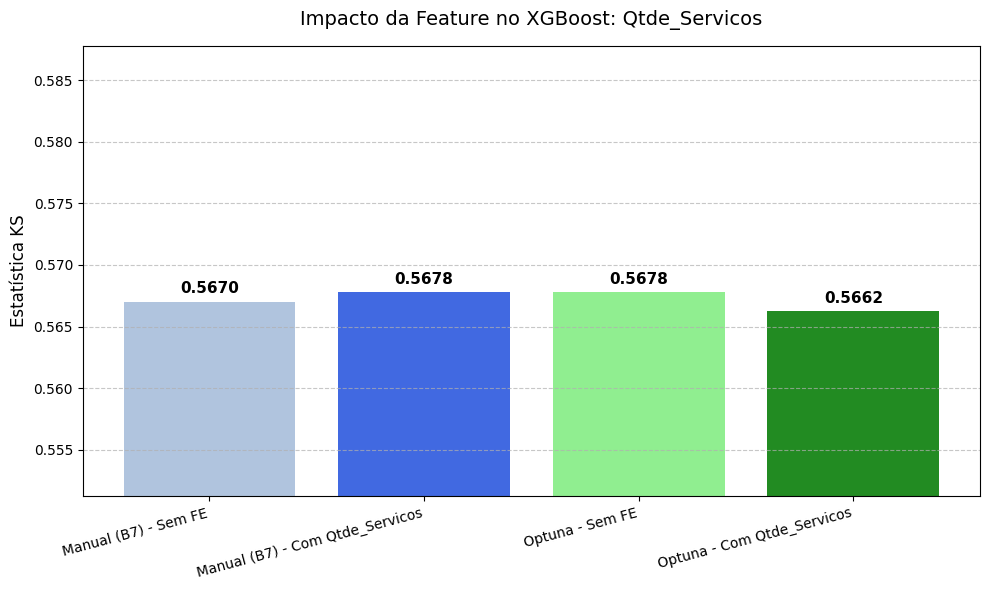

In [ ]:
df_fe1 = df_base.copy()
cols_cat_fe1 = colunas_categoricas_base.copy()
cols_num_fe1 = colunas_numericas_base.copy()

colunas_servicos = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
df_fe1['Qtde_Servicos'] = df_fe1[colunas_servicos].apply(lambda linha: (linha == 'Yes').sum(), axis=1)
cols_num_fe1.append('Qtde_Servicos')

df_train_fe1, df_val_fe1, df_test_fe1 = realizar_split(df_fe1)
X_train_fe1, y_train_fe1, X_val_fe1, y_val_fe1, X_test_fe1, y_test_fe1 = aplicar_pipeline_e_oversampling_xgb(
    df_train_fe1, df_val_fe1, df_test_fe1, cols_cat_fe1, cols_num_fe1
)
print(f"Colunas FE1: {X_train_fe1.shape[1]}")

resultado_fe1_manual = executar_experimento_xgb("XGB_FE1_BaseB7", **params_manual_campeao, X_train=X_train_fe1, y_train=y_train_fe1, X_val=X_val_fe1, y_val=y_val_fe1)
resultado_fe1_optuna = executar_experimento_xgb("XGB_FE1_BaseOptuna", **best_trial_xgb.params, X_train=X_train_fe1, y_train=y_train_fe1, X_val=X_val_fe1, y_val=y_val_fe1)
plot_feature_engineering_comparison_xgb("Qtde_Servicos", ks_b7_base, resultado_fe1_manual['val_ks'], ks_optuna_base_xgb, resultado_fe1_optuna['val_ks'])

### Optuna FE_1 (Qtde_Servicos)

[I 2026-11-26 01:36:48,696] A new study created in RDB with name: Otimizacao_XGB_FE1


Iniciando/Retomando Optuna para: Otimizacao_XGB_FE1 (concluídos: 0 | restantes: 100)...

------------------------------------------------------------------------------------------------------------------------
EXP XGB: Optuna_XGB_FE1_Trial_0 | LR: 0.0164 | Est: 2862 | Depth: 3 | MinChildW: 52 | Sub: 0.57 | ColTree: 0.49 | L2: 15.96


[I 2026-11-26 01:36:53,933] Trial 0 finished with value: 0.5491866769945778 and parameters: {'learning_rate': 0.016440479761182902, 'n_estimators': 2862, 'max_depth': 3, 'min_child_weight': 52, 'subsample': 0.5702083881990965, 'colsample_bytree': 0.49359671220172163, 'colsample_bylevel': 0.5290418060840998, 'gamma': 4.330880728874676, 'reg_alpha': 0.2537815508265665, 'reg_lambda': 15.958573588141263}. Best is trial 0 with value: 0.5491866769945778.


Resultados: Val Loss: 0.4852 | KS: 0.5492 | AUC: 0.8473 | Train MSE: 0.1509 | Val MSE: 0.1585 | F1: 0.7723 | Tempo: 4.84s
Árvores mantidas (Early Stopping Externo): 558 / 2862

------------------------------------------------------------------------------------------------------------------------
EXP XGB: Optuna_XGB_FE1_Trial_1 | LR: 0.0053 | Est: 2916 | Depth: 4 | MinChildW: 25 | Sub: 0.58 | ColTree: 0.51 | L2: 3.12


[I 2026-11-26 01:36:56,333] Trial 1 finished with value: 0.557707203718048 and parameters: {'learning_rate': 0.005338029318481386, 'n_estimators': 2916, 'max_depth': 4, 'min_child_weight': 25, 'subsample': 0.5818212352431953, 'colsample_bytree': 0.5100427059120604, 'colsample_bylevel': 0.6521211214797689, 'gamma': 2.6237821581611893, 'reg_alpha': 0.05342937261279776, 'reg_lambda': 3.124565071260871}. Best is trial 1 with value: 0.557707203718048.


Resultados: Val Loss: 0.4874 | KS: 0.5577 | AUC: 0.8461 | Train MSE: 0.1455 | Val MSE: 0.1591 | F1: 0.7790 | Tempo: 2.02s
Árvores mantidas (Early Stopping Externo): 867 / 2916

------------------------------------------------------------------------------------------------------------------------
EXP XGB: Optuna_XGB_FE1_Trial_2 | LR: 0.0350 | Est: 590 | Depth: 2 | MinChildW: 36 | Sub: 0.71 | ColTree: 0.87 | L2: 1.20


... (192 outputs left out)

[I 2026-11-26 01:39:08,959] Trial 98 finished with value: 0.5600309837335399 and parameters: {'learning_rate': 0.09321845179800442, 'n_estimators': 875, 'max_depth': 1, 'min_child_weight': 54, 'subsample': 0.7775418786069074, 'colsample_bytree': 0.9837915917302108, 'colsample_bylevel': 0.6880671539702243, 'gamma': 0.4095490734705626, 'reg_alpha': 0.6346217103496651, 'reg_lambda': 10.742447646955956}. Best is trial 27 with value: 0.5662277304415182.


Resultados: Val Loss: 0.4837 | KS: 0.5600 | AUC: 0.8480 | Train MSE: 0.1523 | Val MSE: 0.1574 | F1: 0.7726 | Tempo: 0.54s
Árvores mantidas (Early Stopping Externo): 235 / 875

------------------------------------------------------------------------------------------------------------------------
EXP XGB: Optuna_XGB_FE1_Trial_99 | LR: 0.0964 | Est: 684 | Depth: 1 | MinChildW: 69 | Sub: 0.79 | ColTree: 0.91 | L2: 11.79


[I 2026-11-26 01:39:09,881] Trial 99 finished with value: 0.557707203718048 and parameters: {'learning_rate': 0.09636413285055972, 'n_estimators': 684, 'max_depth': 1, 'min_child_weight': 69, 'subsample': 0.7917954511699271, 'colsample_bytree': 0.9100861399386133, 'colsample_bylevel': 0.6619638898053521, 'gamma': 0.41919190609156576, 'reg_alpha': 0.5276548575296985, 'reg_lambda': 11.791367799431812}. Best is trial 27 with value: 0.5662277304415182.


Resultados: Val Loss: 0.4848 | KS: 0.5577 | AUC: 0.8473 | Train MSE: 0.1529 | Val MSE: 0.1580 | F1: 0.7750 | Tempo: 0.44s
Árvores mantidas (Early Stopping Externo): 182 / 684

=== MELHOR MODELO ENCONTRADO (Otimizacao_XGB_FE1): KS 0.5662 (Trial 27) ===
    learning_rate: 0.11604490600068405
    n_estimators: 676
    max_depth: 1
    min_child_weight: 71
    subsample: 0.7485306479096294
    colsample_bytree: 0.9285559713446857
    colsample_bylevel: 0.7301926184995897
    gamma: 0.5084755020618441
    reg_alpha: 0.2236198614844816
    reg_lambda: 10.442361658975804

VENCEDOR DA BATERIA: Optuna_XGB_FE1_Trial_27 (KS Máximo: 0.5662)


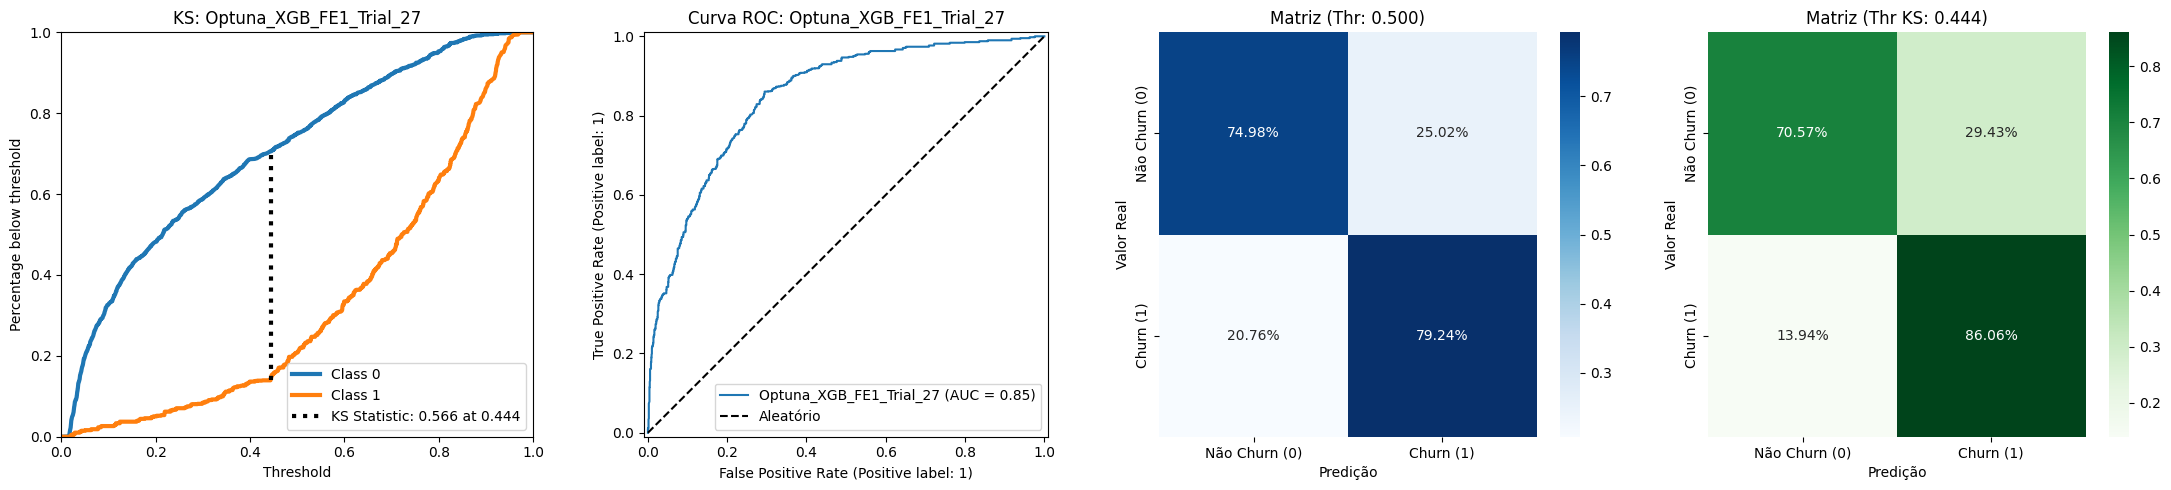

--- MÉTRICAS COM THRESHOLD PADRÃO (0.500) ---
KS: 0.5662 | AUROC: 0.8488 | MSE: 0.1572 | Log-Loss: 0.4829 | Acurácia: 0.7711
Precisão: 0.7600 | Recall: 0.7924 | F1-Score: 0.7759

               precision    recall  f1-score   support

Não Churn (0)       0.78      0.75      0.77      1291
    Churn (1)       0.76      0.79      0.78      1291

     accuracy                           0.77      2582
    macro avg       0.77      0.77      0.77      2582
 weighted avg       0.77      0.77      0.77      2582


--- MÉTRICAS COM THRESHOLD OTIMIZADO PELO KS (0.444) ---
KS: 0.5662 | AUROC: 0.8488 | Acurácia: 0.7831
Precisão: 0.7451 | Recall: 0.8606 | F1-Score: 0.7987

               precision    recall  f1-score   support

Não Churn (0)       0.84      0.71      0.76      1291
    Churn (1)       0.75      0.86      0.80      1291

     accuracy                           0.78      2582
    macro avg       0.79      0.78      0.78      2582
 weighted avg       0.79      0.78      0.78      258

In [ ]:
study_fe1_xgb = rodar_optuna_e_avaliar_xgb("Otimizacao_XGB_FE1", X_train_fe1, y_train_fe1, X_val_fe1, y_val_fe1, "Optuna_XGB_FE1_Trial")

##FE_2: Tenure Binning (6 em 6 meses)

Colunas FE2: 46

------------------------------------------------------------------------------------------------------------------------
EXP XGB: XGB_FE2_BaseB7 | LR: 0.1000 | Est: 300 | Depth: 1 | MinChildW: 80 | Sub: 0.80 | ColTree: 1.00 | L2: 0.10
Resultados: Val Loss: 0.4832 | KS: 0.5670 | AUC: 0.8481 | Train MSE: 0.1522 | Val MSE: 0.1574 | F1: 0.7736 | Tempo: 0.54s
Árvores mantidas (Early Stopping Externo): 217 / 300

------------------------------------------------------------------------------------------------------------------------
EXP XGB: XGB_FE2_BaseOptuna | LR: 0.0473 | Est: 645 | Depth: 2 | MinChildW: 44 | Sub: 0.76 | ColTree: 0.94 | L2: 2.38
Resultados: Val Loss: 0.4853 | KS: 0.5600 | AUC: 0.8486 | Train MSE: 0.1493 | Val MSE: 0.1577 | F1: 0.7810 | Tempo: 0.56s
Árvores mantidas (Early Stopping Externo): 190 / 645


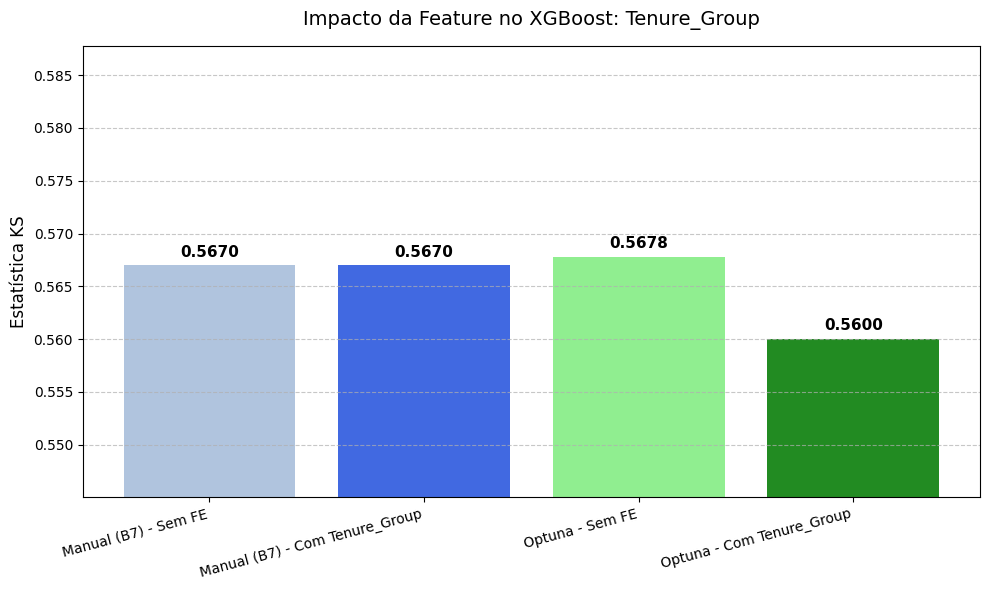

In [ ]:
df_fe2 = df_base.copy()
cols_cat_fe2 = colunas_categoricas_base.copy()
cols_num_fe2 = colunas_numericas_base.copy()

bins = [0, 6, 12, 18, 24, 30, 78]
labels = ['0-6m', '7-12m', '13-18m', '19-24m', '25-30m', '30+m']
df_fe2['Tenure_Group'] = pd.cut(df_fe2['tenure'], bins=bins, labels=labels, right=True, include_lowest=True)
cols_cat_fe2.append('Tenure_Group')

df_train_fe2, df_val_fe2, df_test_fe2 = realizar_split(df_fe2)
X_train_fe2, y_train_fe2, X_val_fe2, y_val_fe2, X_test_fe2, y_test_fe2 = aplicar_pipeline_e_oversampling_xgb(
    df_train_fe2, df_val_fe2, df_test_fe2, cols_cat_fe2, cols_num_fe2
)
print(f"Colunas FE2: {X_train_fe2.shape[1]}")

resultado_fe2_manual = executar_experimento_xgb("XGB_FE2_BaseB7", **params_manual_campeao, X_train=X_train_fe2, y_train=y_train_fe2, X_val=X_val_fe2, y_val=y_val_fe2)
resultado_fe2_optuna = executar_experimento_xgb("XGB_FE2_BaseOptuna", **best_trial_xgb.params, X_train=X_train_fe2, y_train=y_train_fe2, X_val=X_val_fe2, y_val=y_val_fe2)
plot_feature_engineering_comparison_xgb("Tenure_Group", ks_b7_base, resultado_fe2_manual['val_ks'], ks_optuna_base_xgb, resultado_fe2_optuna['val_ks'])

### Optuna FE_2 (Tenure Binning)

[I 2026-11-26 01:39:12,979] A new study created in RDB with name: Otimizacao_XGB_FE2


Iniciando/Retomando Optuna para: Otimizacao_XGB_FE2 (concluídos: 0 | restantes: 100)...

------------------------------------------------------------------------------------------------------------------------
EXP XGB: Optuna_XGB_FE2_Trial_0 | LR: 0.0164 | Est: 2862 | Depth: 3 | MinChildW: 52 | Sub: 0.57 | ColTree: 0.49 | L2: 15.96


[I 2026-11-26 01:39:14,472] Trial 0 finished with value: 0.5515104570100697 and parameters: {'learning_rate': 0.016440479761182902, 'n_estimators': 2862, 'max_depth': 3, 'min_child_weight': 52, 'subsample': 0.5702083881990965, 'colsample_bytree': 0.49359671220172163, 'colsample_bylevel': 0.5290418060840998, 'gamma': 4.330880728874676, 'reg_alpha': 0.2537815508265665, 'reg_lambda': 15.958573588141263}. Best is trial 0 with value: 0.5515104570100697.


Resultados: Val Loss: 0.4865 | KS: 0.5515 | AUC: 0.8468 | Train MSE: 0.1516 | Val MSE: 0.1589 | F1: 0.7721 | Tempo: 1.06s
Árvores mantidas (Early Stopping Externo): 416 / 2862

------------------------------------------------------------------------------------------------------------------------
EXP XGB: Optuna_XGB_FE2_Trial_1 | LR: 0.0053 | Est: 2916 | Depth: 4 | MinChildW: 25 | Sub: 0.58 | ColTree: 0.51 | L2: 3.12


[I 2026-11-26 01:39:20,651] Trial 1 finished with value: 0.5561580170410535 and parameters: {'learning_rate': 0.005338029318481386, 'n_estimators': 2916, 'max_depth': 4, 'min_child_weight': 25, 'subsample': 0.5818212352431953, 'colsample_bytree': 0.5100427059120604, 'colsample_bylevel': 0.6521211214797689, 'gamma': 2.6237821581611893, 'reg_alpha': 0.05342937261279776, 'reg_lambda': 3.124565071260871}. Best is trial 1 with value: 0.5561580170410535.


Resultados: Val Loss: 0.4864 | KS: 0.5562 | AUC: 0.8468 | Train MSE: 0.1460 | Val MSE: 0.1586 | F1: 0.7797 | Tempo: 5.74s
Árvores mantidas (Early Stopping Externo): 875 / 2916

------------------------------------------------------------------------------------------------------------------------
EXP XGB: Optuna_XGB_FE2_Trial_2 | LR: 0.0350 | Est: 590 | Depth: 2 | MinChildW: 36 | Sub: 0.71 | ColTree: 0.87 | L2: 1.20


... (192 outputs left out)

[I 2026-11-26 01:41:38,391] Trial 98 finished with value: 0.5639039504260264 and parameters: {'learning_rate': 0.046098784867785916, 'n_estimators': 711, 'max_depth': 2, 'min_child_weight': 76, 'subsample': 0.8246290154495467, 'colsample_bytree': 0.9281165970966948, 'colsample_bylevel': 0.5012896142944251, 'gamma': 0.30804677799076974, 'reg_alpha': 0.6982219397732136, 'reg_lambda': 2.402621497780798}. Best is trial 50 with value: 0.5716498838109992.


Resultados: Val Loss: 0.4856 | KS: 0.5639 | AUC: 0.8478 | Train MSE: 0.1493 | Val MSE: 0.1581 | F1: 0.7746 | Tempo: 0.59s
Árvores mantidas (Early Stopping Externo): 223 / 711

------------------------------------------------------------------------------------------------------------------------
EXP XGB: Optuna_XGB_FE2_Trial_99 | LR: 0.0435 | Est: 669 | Depth: 2 | MinChildW: 70 | Sub: 0.85 | ColTree: 0.95 | L2: 4.61


[I 2026-11-26 01:41:39,575] Trial 99 finished with value: 0.5639039504260264 and parameters: {'learning_rate': 0.04347818877083084, 'n_estimators': 669, 'max_depth': 2, 'min_child_weight': 70, 'subsample': 0.8537127292416125, 'colsample_bytree': 0.951008007427368, 'colsample_bylevel': 0.5282306666507451, 'gamma': 0.41526874201234865, 'reg_alpha': 0.33837515031109106, 'reg_lambda': 4.610235245467432}. Best is trial 50 with value: 0.5716498838109992.


Resultados: Val Loss: 0.4842 | KS: 0.5639 | AUC: 0.8488 | Train MSE: 0.1493 | Val MSE: 0.1575 | F1: 0.7743 | Tempo: 0.64s
Árvores mantidas (Early Stopping Externo): 242 / 669

=== MELHOR MODELO ENCONTRADO (Otimizacao_XGB_FE2): KS 0.5716 (Trial 50) ===
    learning_rate: 0.0389366390639333
    n_estimators: 373
    max_depth: 2
    min_child_weight: 57
    subsample: 0.8580830071611962
    colsample_bytree: 0.9704455887462209
    colsample_bylevel: 0.5648399899998865
    gamma: 0.3882246222311741
    reg_alpha: 0.22776474331133104
    reg_lambda: 3.072802298428584

VENCEDOR DA BATERIA: Optuna_XGB_FE2_Trial_50 (KS Máximo: 0.5716)


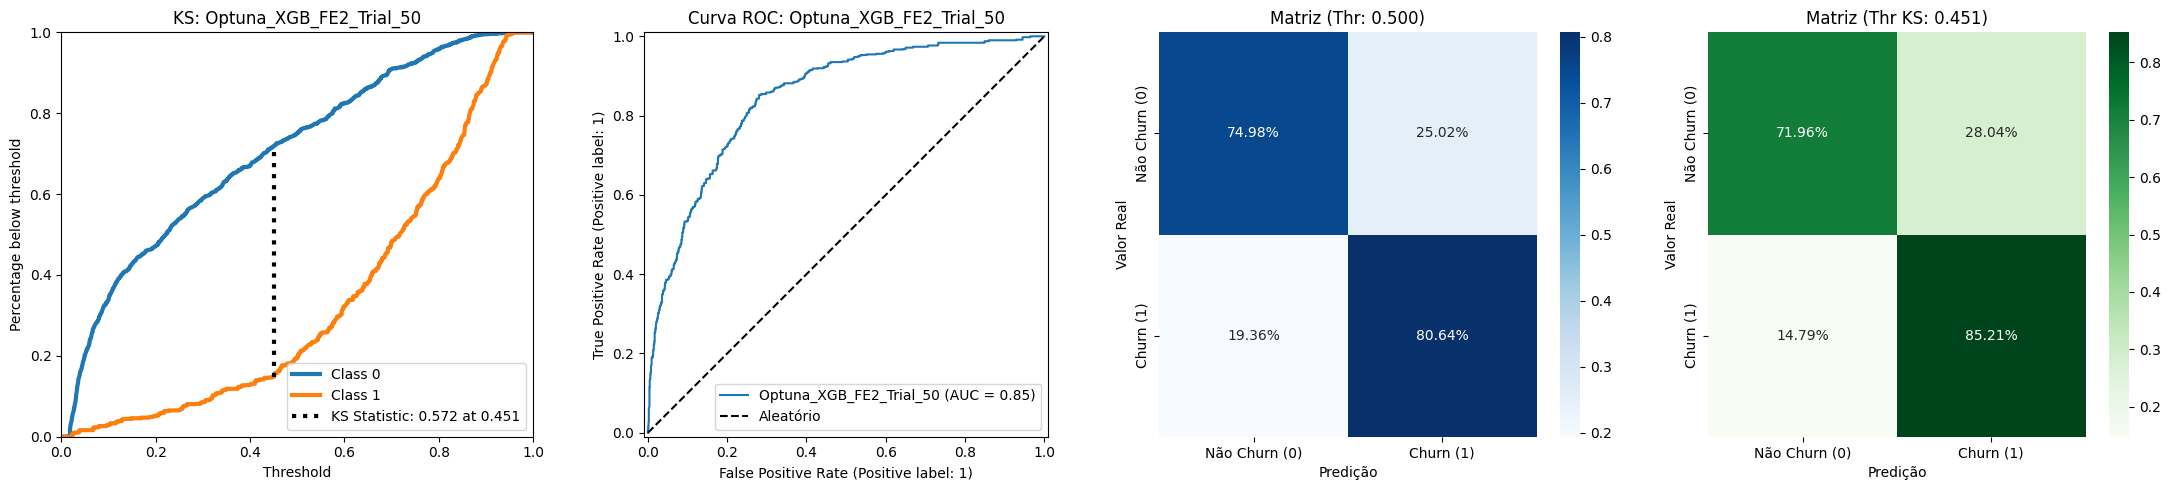

--- MÉTRICAS COM THRESHOLD PADRÃO (0.500) ---
KS: 0.5716 | AUROC: 0.8483 | MSE: 0.1576 | Log-Loss: 0.4856 | Acurácia: 0.7781
Precisão: 0.7632 | Recall: 0.8064 | F1-Score: 0.7842

               precision    recall  f1-score   support

Não Churn (0)       0.79      0.75      0.77      1291
    Churn (1)       0.76      0.81      0.78      1291

     accuracy                           0.78      2582
    macro avg       0.78      0.78      0.78      2582
 weighted avg       0.78      0.78      0.78      2582


--- MÉTRICAS COM THRESHOLD OTIMIZADO PELO KS (0.451) ---
KS: 0.5716 | AUROC: 0.8483 | Acurácia: 0.7858
Precisão: 0.7524 | Recall: 0.8521 | F1-Score: 0.7991

               precision    recall  f1-score   support

Não Churn (0)       0.83      0.72      0.77      1291
    Churn (1)       0.75      0.85      0.80      1291

     accuracy                           0.79      2582
    macro avg       0.79      0.79      0.78      2582
 weighted avg       0.79      0.79      0.78      258

In [ ]:
study_fe2_xgb = rodar_optuna_e_avaliar_xgb("Otimizacao_XGB_FE2", X_train_fe2, y_train_fe2, X_val_fe2, y_val_fe2, "Optuna_XGB_FE2_Trial")

## FE_3: Proporção de Gasto (Gasto_Medio_Real)

Colunas FE3: 41

------------------------------------------------------------------------------------------------------------------------
EXP XGB: XGB_FE3_BaseB7 | LR: 0.1000 | Est: 300 | Depth: 1 | MinChildW: 80 | Sub: 0.80 | ColTree: 1.00 | L2: 0.10
Resultados: Val Loss: 0.4834 | KS: 0.5647 | AUC: 0.8480 | Train MSE: 0.1523 | Val MSE: 0.1574 | F1: 0.7742 | Tempo: 0.46s
Árvores mantidas (Early Stopping Externo): 188 / 300

------------------------------------------------------------------------------------------------------------------------
EXP XGB: XGB_FE3_BaseOptuna | LR: 0.0473 | Est: 645 | Depth: 2 | MinChildW: 44 | Sub: 0.76 | ColTree: 0.94 | L2: 2.38
Resultados: Val Loss: 0.4865 | KS: 0.5593 | AUC: 0.8475 | Train MSE: 0.1489 | Val MSE: 0.1579 | F1: 0.7800 | Tempo: 1.25s
Árvores mantidas (Early Stopping Externo): 185 / 645


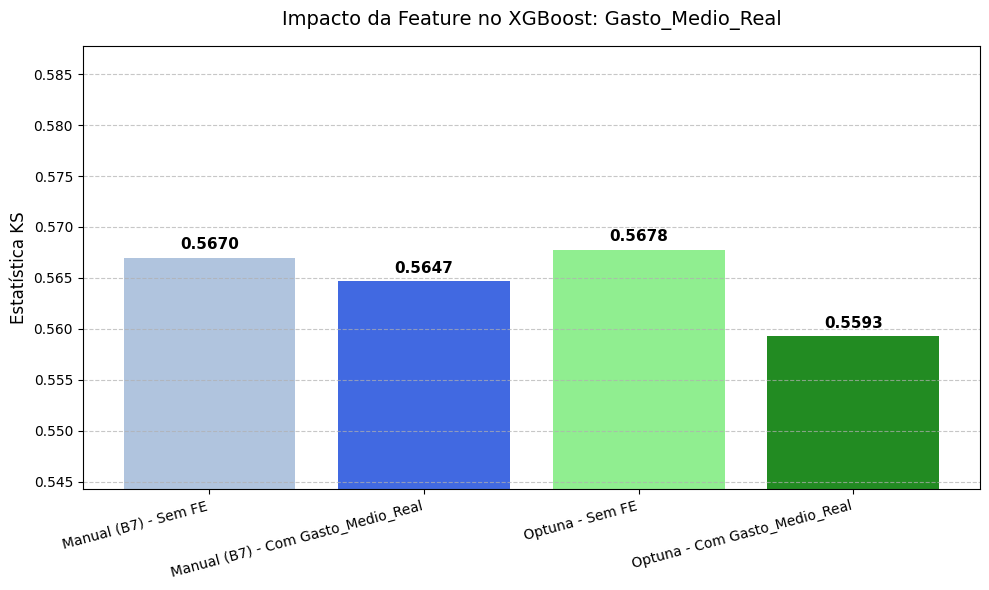

In [ ]:
df_fe3 = df_base.copy()
cols_cat_fe3 = colunas_categoricas_base.copy()
cols_num_fe3 = colunas_numericas_base.copy()

df_fe3['Gasto_Medio_Real'] = np.where(df_fe3['tenure'] == 0, 0, df_fe3['TotalCharges'] / df_fe3['tenure'])
cols_num_fe3.append('Gasto_Medio_Real')

df_train_fe3, df_val_fe3, df_test_fe3 = realizar_split(df_fe3)
X_train_fe3, y_train_fe3, X_val_fe3, y_val_fe3, X_test_fe3, y_test_fe3 = aplicar_pipeline_e_oversampling_xgb(
    df_train_fe3, df_val_fe3, df_test_fe3, cols_cat_fe3, cols_num_fe3
)
print(f"Colunas FE3: {X_train_fe3.shape[1]}")

resultado_fe3_manual = executar_experimento_xgb("XGB_FE3_BaseB7", **params_manual_campeao, X_train=X_train_fe3, y_train=y_train_fe3, X_val=X_val_fe3, y_val=y_val_fe3)
resultado_fe3_optuna = executar_experimento_xgb("XGB_FE3_BaseOptuna", **best_trial_xgb.params, X_train=X_train_fe3, y_train=y_train_fe3, X_val=X_val_fe3, y_val=y_val_fe3)
plot_feature_engineering_comparison_xgb("Gasto_Medio_Real", ks_b7_base, resultado_fe3_manual['val_ks'], ks_optuna_base_xgb, resultado_fe3_optuna['val_ks'])

### Optuna FE_3 (Proporção de Gasto)

[I 2026-11-26 01:41:43,479] A new study created in RDB with name: Otimizacao_XGB_FE3


Iniciando/Retomando Optuna para: Otimizacao_XGB_FE3 (concluídos: 0 | restantes: 100)...

------------------------------------------------------------------------------------------------------------------------
EXP XGB: Optuna_XGB_FE3_Trial_0 | LR: 0.0164 | Est: 2862 | Depth: 3 | MinChildW: 52 | Sub: 0.57 | ColTree: 0.49 | L2: 15.96


[I 2026-11-26 01:41:47,053] Trial 0 finished with value: 0.5538342370255616 and parameters: {'learning_rate': 0.016440479761182902, 'n_estimators': 2862, 'max_depth': 3, 'min_child_weight': 52, 'subsample': 0.5702083881990965, 'colsample_bytree': 0.49359671220172163, 'colsample_bylevel': 0.5290418060840998, 'gamma': 4.330880728874676, 'reg_alpha': 0.2537815508265665, 'reg_lambda': 15.958573588141263}. Best is trial 0 with value: 0.5538342370255616.


Resultados: Val Loss: 0.4857 | KS: 0.5538 | AUC: 0.8469 | Train MSE: 0.1507 | Val MSE: 0.1586 | F1: 0.7750 | Tempo: 3.08s
Árvores mantidas (Early Stopping Externo): 643 / 2862

------------------------------------------------------------------------------------------------------------------------
EXP XGB: Optuna_XGB_FE3_Trial_1 | LR: 0.0053 | Est: 2916 | Depth: 4 | MinChildW: 25 | Sub: 0.58 | ColTree: 0.51 | L2: 3.12


[I 2026-11-26 01:41:49,638] Trial 1 finished with value: 0.5530596436870643 and parameters: {'learning_rate': 0.005338029318481386, 'n_estimators': 2916, 'max_depth': 4, 'min_child_weight': 25, 'subsample': 0.5818212352431953, 'colsample_bytree': 0.5100427059120604, 'colsample_bylevel': 0.6521211214797689, 'gamma': 2.6237821581611893, 'reg_alpha': 0.05342937261279776, 'reg_lambda': 3.124565071260871}. Best is trial 0 with value: 0.5538342370255616.


Resultados: Val Loss: 0.4891 | KS: 0.5531 | AUC: 0.8447 | Train MSE: 0.1450 | Val MSE: 0.1596 | F1: 0.7709 | Tempo: 2.16s
Árvores mantidas (Early Stopping Externo): 863 / 2916

------------------------------------------------------------------------------------------------------------------------
EXP XGB: Optuna_XGB_FE3_Trial_2 | LR: 0.0350 | Est: 590 | Depth: 2 | MinChildW: 36 | Sub: 0.71 | ColTree: 0.87 | L2: 1.20


... (192 outputs left out)

[I 2026-11-26 01:43:42,224] Trial 98 finished with value: 0.5553834237025561 and parameters: {'learning_rate': 0.06097576658555362, 'n_estimators': 933, 'max_depth': 4, 'min_child_weight': 61, 'subsample': 0.736422083324281, 'colsample_bytree': 0.9597012654818566, 'colsample_bylevel': 0.5301682553007857, 'gamma': 0.08696853771890514, 'reg_alpha': 0.0023792077842462495, 'reg_lambda': 1.5696807931372272}. Best is trial 89 with value: 0.570875290472502.


Resultados: Val Loss: 0.4886 | KS: 0.5554 | AUC: 0.8453 | Train MSE: 0.1470 | Val MSE: 0.1592 | F1: 0.7747 | Tempo: 1.36s
Árvores mantidas (Early Stopping Externo): 75 / 933

------------------------------------------------------------------------------------------------------------------------
EXP XGB: Optuna_XGB_FE3_Trial_99 | LR: 0.0715 | Est: 837 | Depth: 4 | MinChildW: 64 | Sub: 0.70 | ColTree: 1.00 | L2: 3.00


[I 2026-11-26 01:43:43,256] Trial 99 finished with value: 0.557707203718048 and parameters: {'learning_rate': 0.07150533213089451, 'n_estimators': 837, 'max_depth': 4, 'min_child_weight': 64, 'subsample': 0.6997570749590991, 'colsample_bytree': 0.9954545957352913, 'colsample_bylevel': 0.5473970837793708, 'gamma': 0.5461017239568429, 'reg_alpha': 0.0026583941558333004, 'reg_lambda': 2.995017318115945}. Best is trial 89 with value: 0.570875290472502.


Resultados: Val Loss: 0.4865 | KS: 0.5577 | AUC: 0.8468 | Train MSE: 0.1449 | Val MSE: 0.1591 | F1: 0.7701 | Tempo: 0.37s
Árvores mantidas (Early Stopping Externo): 96 / 837

=== MELHOR MODELO ENCONTRADO (Otimizacao_XGB_FE3): KS 0.5709 (Trial 89) ===
    learning_rate: 0.0611498489622592
    n_estimators: 1747
    max_depth: 4
    min_child_weight: 74
    subsample: 0.8688038262333795
    colsample_bytree: 0.9598385774702223
    colsample_bylevel: 0.6855235339419283
    gamma: 1.626148790490621
    reg_alpha: 0.0020047592000193687
    reg_lambda: 4.1233839291561765

VENCEDOR DA BATERIA: Optuna_XGB_FE3_Trial_89 (KS Máximo: 0.5709)


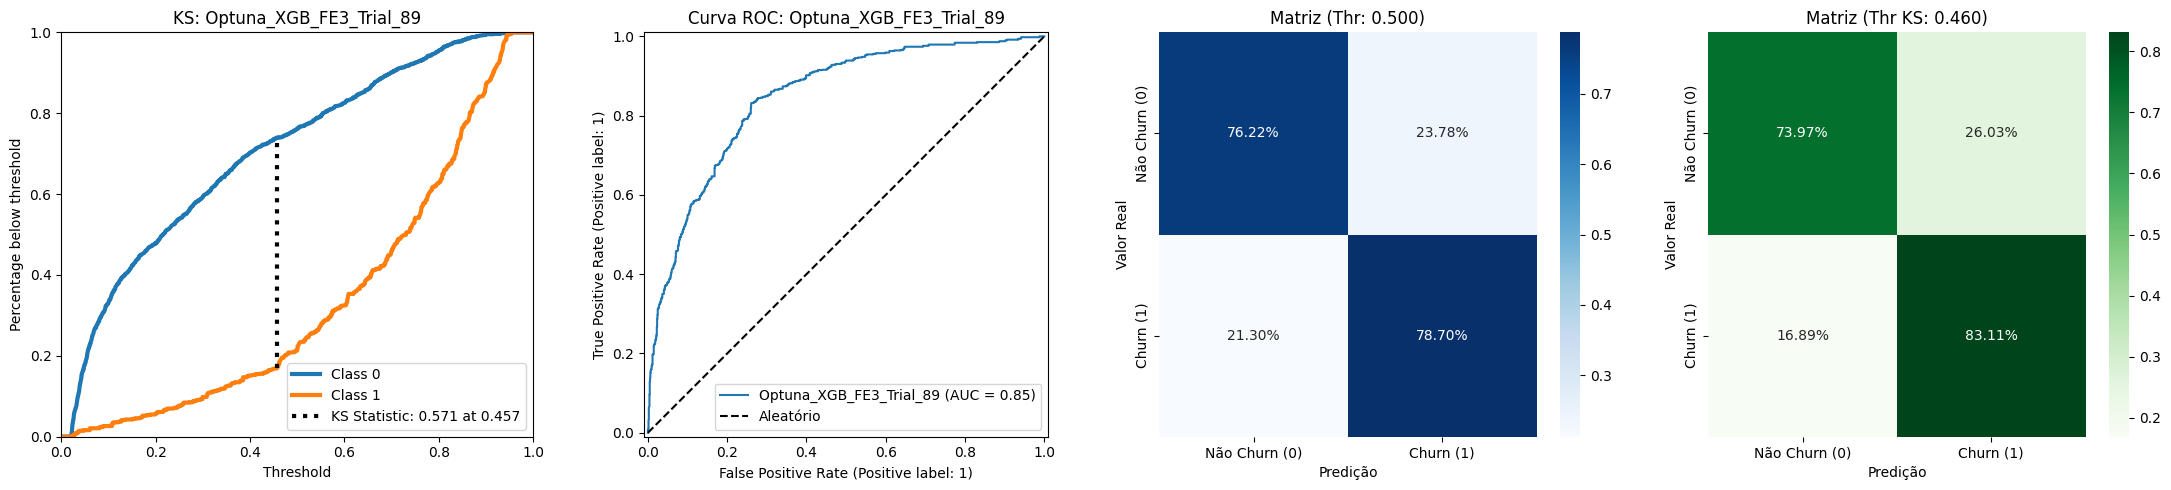

--- MÉTRICAS COM THRESHOLD PADRÃO (0.500) ---
KS: 0.5709 | AUROC: 0.8460 | MSE: 0.1590 | Log-Loss: 0.4885 | Acurácia: 0.7746
Precisão: 0.7680 | Recall: 0.7870 | F1-Score: 0.7774

               precision    recall  f1-score   support

Não Churn (0)       0.78      0.76      0.77      1291
    Churn (1)       0.77      0.79      0.78      1291

     accuracy                           0.77      2582
    macro avg       0.77      0.77      0.77      2582
 weighted avg       0.77      0.77      0.77      2582


--- MÉTRICAS COM THRESHOLD OTIMIZADO PELO KS (0.460) ---
KS: 0.5709 | AUROC: 0.8460 | Acurácia: 0.7854
Precisão: 0.7615 | Recall: 0.8311 | F1-Score: 0.7948

               precision    recall  f1-score   support

Não Churn (0)       0.81      0.74      0.78      1291
    Churn (1)       0.76      0.83      0.79      1291

     accuracy                           0.79      2582
    macro avg       0.79      0.79      0.78      2582
 weighted avg       0.79      0.79      0.78      258

In [ ]:
study_fe3_xgb = rodar_optuna_e_avaliar_xgb("Otimizacao_XGB_FE3", X_train_fe3, y_train_fe3, X_val_fe3, y_val_fe3, "Optuna_XGB_FE3_Trial")

## FE_4: Família (Partner + Dependents)

Colunas FE4: 41

------------------------------------------------------------------------------------------------------------------------
EXP XGB: XGB_FE4_BaseB7 | LR: 0.1000 | Est: 300 | Depth: 1 | MinChildW: 80 | Sub: 0.80 | ColTree: 1.00 | L2: 0.10
Resultados: Val Loss: 0.4833 | KS: 0.5662 | AUC: 0.8481 | Train MSE: 0.1525 | Val MSE: 0.1574 | F1: 0.7692 | Tempo: 0.47s
Árvores mantidas (Early Stopping Externo): 188 / 300

------------------------------------------------------------------------------------------------------------------------
EXP XGB: XGB_FE4_BaseOptuna | LR: 0.0473 | Est: 645 | Depth: 2 | MinChildW: 44 | Sub: 0.76 | ColTree: 0.94 | L2: 2.38
Resultados: Val Loss: 0.4869 | KS: 0.5562 | AUC: 0.8472 | Train MSE: 0.1490 | Val MSE: 0.1584 | F1: 0.7729 | Tempo: 0.50s
Árvores mantidas (Early Stopping Externo): 187 / 645


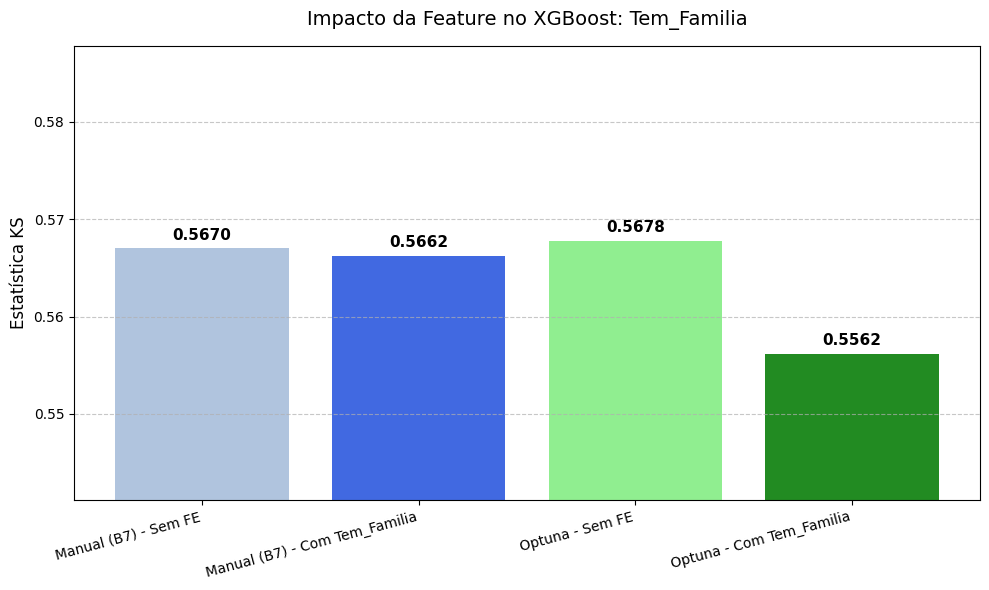

In [ ]:
df_fe4 = df_base.copy()
cols_cat_fe4 = colunas_categoricas_base.copy()
cols_num_fe4 = colunas_numericas_base.copy()

df_fe4['Tem_Familia'] = ((df_fe4['Partner'] == 'Yes') | (df_fe4['Dependents'] == 'Yes')).map({True: 'Yes', False: 'No'})
cols_cat_fe4.append('Tem_Familia')

df_train_fe4, df_val_fe4, df_test_fe4 = realizar_split(df_fe4)
X_train_fe4, y_train_fe4, X_val_fe4, y_val_fe4, X_test_fe4, y_test_fe4 = aplicar_pipeline_e_oversampling_xgb(
    df_train_fe4, df_val_fe4, df_test_fe4, cols_cat_fe4, cols_num_fe4
)
print(f"Colunas FE4: {X_train_fe4.shape[1]}")

resultado_fe4_manual = executar_experimento_xgb("XGB_FE4_BaseB7", **params_manual_campeao, X_train=X_train_fe4, y_train=y_train_fe4, X_val=X_val_fe4, y_val=y_val_fe4)
resultado_fe4_optuna = executar_experimento_xgb("XGB_FE4_BaseOptuna", **best_trial_xgb.params, X_train=X_train_fe4, y_train=y_train_fe4, X_val=X_val_fe4, y_val=y_val_fe4)
plot_feature_engineering_comparison_xgb("Tem_Familia", ks_b7_base, resultado_fe4_manual['val_ks'], ks_optuna_base_xgb, resultado_fe4_optuna['val_ks'])

### Optuna FE_4 (Família)

[I 2026-11-26 01:43:46,215] A new study created in RDB with name: Otimizacao_XGB_FE4


Iniciando/Retomando Optuna para: Otimizacao_XGB_FE4 (concluídos: 0 | restantes: 100)...

------------------------------------------------------------------------------------------------------------------------
EXP XGB: Optuna_XGB_FE4_Trial_0 | LR: 0.0164 | Est: 2862 | Depth: 3 | MinChildW: 52 | Sub: 0.57 | ColTree: 0.49 | L2: 15.96


[I 2026-11-26 01:43:47,876] Trial 0 finished with value: 0.5546088303640588 and parameters: {'learning_rate': 0.016440479761182902, 'n_estimators': 2862, 'max_depth': 3, 'min_child_weight': 52, 'subsample': 0.5702083881990965, 'colsample_bytree': 0.49359671220172163, 'colsample_bylevel': 0.5290418060840998, 'gamma': 4.330880728874676, 'reg_alpha': 0.2537815508265665, 'reg_lambda': 15.958573588141263}. Best is trial 0 with value: 0.5546088303640588.


Resultados: Val Loss: 0.4850 | KS: 0.5546 | AUC: 0.8477 | Train MSE: 0.1510 | Val MSE: 0.1583 | F1: 0.7714 | Tempo: 1.20s
Árvores mantidas (Early Stopping Externo): 561 / 2862

------------------------------------------------------------------------------------------------------------------------
EXP XGB: Optuna_XGB_FE4_Trial_1 | LR: 0.0053 | Est: 2916 | Depth: 4 | MinChildW: 25 | Sub: 0.58 | ColTree: 0.51 | L2: 3.12


[I 2026-11-26 01:43:50,805] Trial 1 finished with value: 0.5569326103795508 and parameters: {'learning_rate': 0.005338029318481386, 'n_estimators': 2916, 'max_depth': 4, 'min_child_weight': 25, 'subsample': 0.5818212352431953, 'colsample_bytree': 0.5100427059120604, 'colsample_bylevel': 0.6521211214797689, 'gamma': 2.6237821581611893, 'reg_alpha': 0.05342937261279776, 'reg_lambda': 3.124565071260871}. Best is trial 1 with value: 0.5569326103795508.


Resultados: Val Loss: 0.4872 | KS: 0.5569 | AUC: 0.8459 | Train MSE: 0.1454 | Val MSE: 0.1590 | F1: 0.7785 | Tempo: 2.46s
Árvores mantidas (Early Stopping Externo): 907 / 2916

------------------------------------------------------------------------------------------------------------------------
EXP XGB: Optuna_XGB_FE4_Trial_2 | LR: 0.0350 | Est: 590 | Depth: 2 | MinChildW: 36 | Sub: 0.71 | ColTree: 0.87 | L2: 1.20


... (192 outputs left out)

[I 2026-11-26 01:46:09,785] Trial 98 finished with value: 0.5631293570875291 and parameters: {'learning_rate': 0.048016445013570545, 'n_estimators': 232, 'max_depth': 2, 'min_child_weight': 55, 'subsample': 0.9036808957627368, 'colsample_bytree': 0.8787737748412106, 'colsample_bylevel': 0.5689998236526471, 'gamma': 0.4415127552544962, 'reg_alpha': 0.33498712157830246, 'reg_lambda': 5.265209028371934}. Best is trial 87 with value: 0.5739736638264911.


Resultados: Val Loss: 0.4862 | KS: 0.5631 | AUC: 0.8478 | Train MSE: 0.1484 | Val MSE: 0.1579 | F1: 0.7807 | Tempo: 0.56s
Árvores mantidas (Early Stopping Externo): 219 / 232

------------------------------------------------------------------------------------------------------------------------
EXP XGB: Optuna_XGB_FE4_Trial_99 | LR: 0.0524 | Est: 227 | Depth: 2 | MinChildW: 55 | Sub: 0.89 | ColTree: 1.00 | L2: 6.33


[I 2026-11-26 01:46:10,926] Trial 99 finished with value: 0.5569326103795508 and parameters: {'learning_rate': 0.0523549819587616, 'n_estimators': 227, 'max_depth': 2, 'min_child_weight': 55, 'subsample': 0.8931819401437644, 'colsample_bytree': 0.9961573529803269, 'colsample_bylevel': 0.5279862520082546, 'gamma': 0.4954181222240728, 'reg_alpha': 0.238505506817846, 'reg_lambda': 6.332528950890977}. Best is trial 87 with value: 0.5739736638264911.


Resultados: Val Loss: 0.4870 | KS: 0.5569 | AUC: 0.8471 | Train MSE: 0.1483 | Val MSE: 0.1582 | F1: 0.7812 | Tempo: 0.54s
Árvores mantidas (Early Stopping Externo): 208 / 227

=== MELHOR MODELO ENCONTRADO (Otimizacao_XGB_FE4): KS 0.5740 (Trial 87) ===
    learning_rate: 0.06919664931050364
    n_estimators: 380
    max_depth: 2
    min_child_weight: 51
    subsample: 0.895096144262079
    colsample_bytree: 0.9152554591924407
    colsample_bylevel: 0.5253192815987798
    gamma: 1.0720664928702943
    reg_alpha: 0.18159975340873077
    reg_lambda: 7.096994287465911

VENCEDOR DA BATERIA: Optuna_XGB_FE4_Trial_87 (KS Máximo: 0.5740)


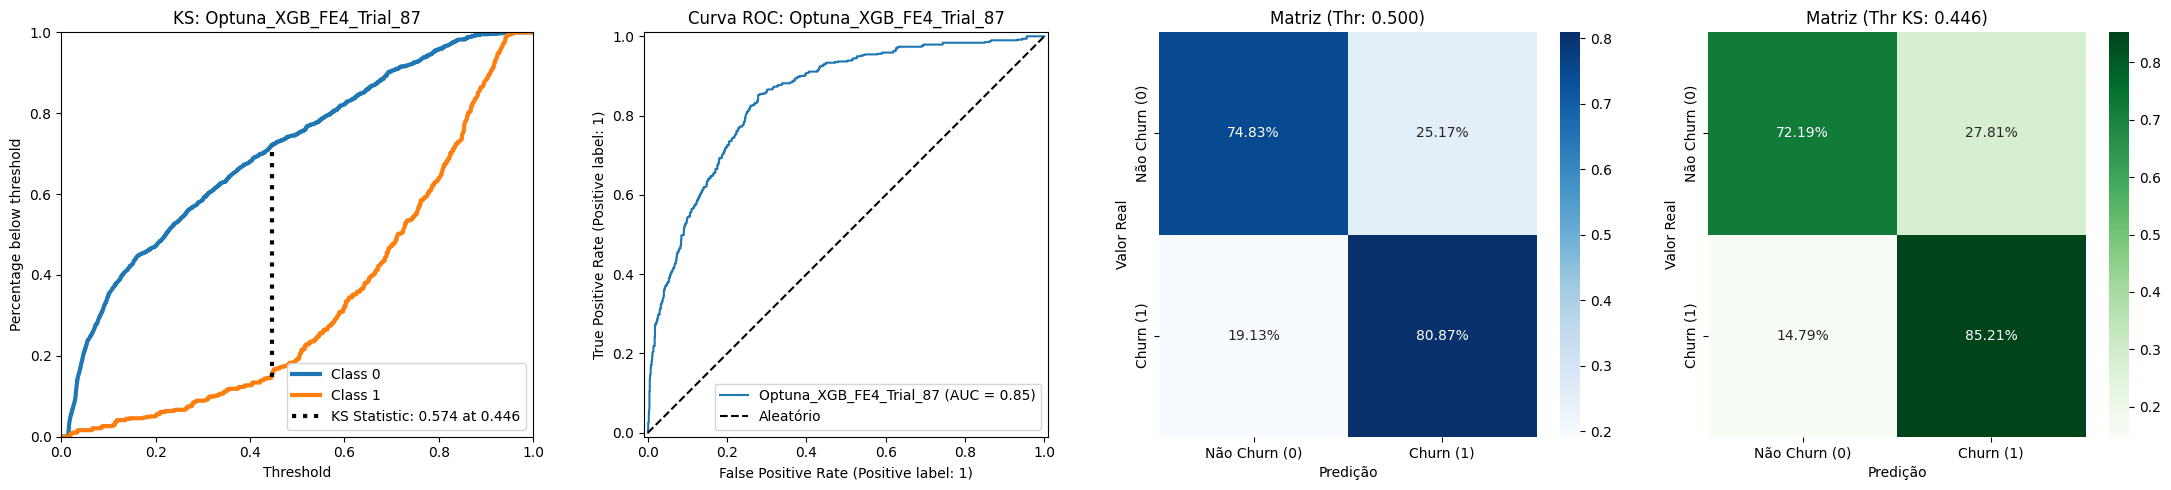

--- MÉTRICAS COM THRESHOLD PADRÃO (0.500) ---
KS: 0.5740 | AUROC: 0.8481 | MSE: 0.1575 | Log-Loss: 0.4859 | Acurácia: 0.7785
Precisão: 0.7626 | Recall: 0.8087 | F1-Score: 0.7850

               precision    recall  f1-score   support

Não Churn (0)       0.80      0.75      0.77      1291
    Churn (1)       0.76      0.81      0.78      1291

     accuracy                           0.78      2582
    macro avg       0.78      0.78      0.78      2582
 weighted avg       0.78      0.78      0.78      2582


--- MÉTRICAS COM THRESHOLD OTIMIZADO PELO KS (0.446) ---
KS: 0.5740 | AUROC: 0.8481 | Acurácia: 0.7870
Precisão: 0.7539 | Recall: 0.8521 | F1-Score: 0.8000

               precision    recall  f1-score   support

Não Churn (0)       0.83      0.72      0.77      1291
    Churn (1)       0.75      0.85      0.80      1291

     accuracy                           0.79      2582
    macro avg       0.79      0.79      0.79      2582
 weighted avg       0.79      0.79      0.79      258

In [ ]:
study_fe4_xgb = rodar_optuna_e_avaliar_xgb("Otimizacao_XGB_FE4", X_train_fe4, y_train_fe4, X_val_fe4, y_val_fe4, "Optuna_XGB_FE4_Trial")

## FE_ALL: Todas as Features Combinadas + Optuna

Colunas FE_ALL: 49

------------------------------------------------------------------------------------------------------------------------
EXP XGB: XGB_FE_ALL_BaseB7 | LR: 0.1000 | Est: 300 | Depth: 1 | MinChildW: 80 | Sub: 0.80 | ColTree: 1.00 | L2: 0.10
Resultados: Val Loss: 0.4834 | KS: 0.5647 | AUC: 0.8480 | Train MSE: 0.1523 | Val MSE: 0.1574 | F1: 0.7742 | Tempo: 0.56s
Árvores mantidas (Early Stopping Externo): 188 / 300

------------------------------------------------------------------------------------------------------------------------
EXP XGB: XGB_FE_ALL_BaseOptuna | LR: 0.0473 | Est: 645 | Depth: 2 | MinChildW: 44 | Sub: 0.76 | ColTree: 0.94 | L2: 2.38
Resultados: Val Loss: 0.4892 | KS: 0.5608 | AUC: 0.8459 | Train MSE: 0.1487 | Val MSE: 0.1588 | F1: 0.7807 | Tempo: 0.57s
Árvores mantidas (Early Stopping Externo): 185 / 645


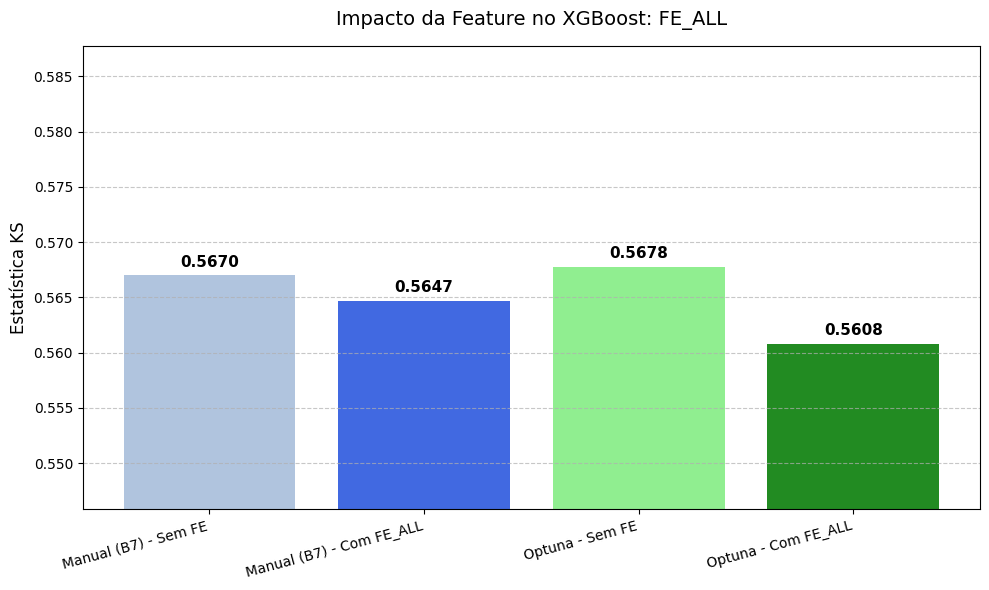

In [ ]:
df_fe_all = df_base.copy()
cols_cat_all = colunas_categoricas_base.copy()
cols_num_all = colunas_numericas_base.copy()

# FE_1: Qtde_Servicos
colunas_servicos = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
df_fe_all['Qtde_Servicos'] = df_fe_all[colunas_servicos].apply(lambda linha: (linha == 'Yes').sum(), axis=1)
cols_num_all.append('Qtde_Servicos')

# FE_2: Tenure Binning
bins = [0, 6, 12, 18, 24, 30, 78]
labels = ['0-6m', '7-12m', '13-18m', '19-24m', '25-30m', '30+m']
df_fe_all['Tenure_Group'] = pd.cut(df_fe_all['tenure'], bins=bins, labels=labels, right=True, include_lowest=True)
cols_cat_all.append('Tenure_Group')

# FE_3: Proporção de Gasto
df_fe_all['Gasto_Medio_Real'] = np.where(df_fe_all['tenure'] == 0, 0, df_fe_all['TotalCharges'] / df_fe_all['tenure'])
cols_num_all.append('Gasto_Medio_Real')

# FE_4: Família
df_fe_all['Tem_Familia'] = ((df_fe_all['Partner'] == 'Yes') | (df_fe_all['Dependents'] == 'Yes')).map({True: 'Yes', False: 'No'})
cols_cat_all.append('Tem_Familia')

df_train_all, df_val_all, df_test_all = realizar_split(df_fe_all)
X_train_all, y_train_all, X_val_all, y_val_all, X_test_all, y_test_all = aplicar_pipeline_e_oversampling_xgb(
    df_train_all, df_val_all, df_test_all, cols_cat_all, cols_num_all
)
print(f"Colunas FE_ALL: {X_train_all.shape[1]}")

resultado_all_manual = executar_experimento_xgb("XGB_FE_ALL_BaseB7", **params_manual_campeao, X_train=X_train_all, y_train=y_train_all, X_val=X_val_all, y_val=y_val_all)
resultado_all_optuna = executar_experimento_xgb("XGB_FE_ALL_BaseOptuna", **best_trial_xgb.params, X_train=X_train_all, y_train=y_train_all, X_val=X_val_all, y_val=y_val_all)
plot_feature_engineering_comparison_xgb("FE_ALL", ks_b7_base, resultado_all_manual['val_ks'], ks_optuna_base_xgb, resultado_all_optuna['val_ks'])

###Optuna FE_ALL

[I 2026-11-26 01:46:15,050] A new study created in RDB with name: Otimizacao_XGB_FE_ALL


Iniciando/Retomando Optuna para: Otimizacao_XGB_FE_ALL (concluídos: 0 | restantes: 100)...

------------------------------------------------------------------------------------------------------------------------
EXP XGB: Optuna_XGB_FE_ALL_Trial_0 | LR: 0.0164 | Est: 2862 | Depth: 3 | MinChildW: 52 | Sub: 0.57 | ColTree: 0.49 | L2: 15.96


[I 2026-11-26 01:46:16,610] Trial 0 finished with value: 0.5546088303640588 and parameters: {'learning_rate': 0.016440479761182902, 'n_estimators': 2862, 'max_depth': 3, 'min_child_weight': 52, 'subsample': 0.5702083881990965, 'colsample_bytree': 0.49359671220172163, 'colsample_bylevel': 0.5290418060840998, 'gamma': 4.330880728874676, 'reg_alpha': 0.2537815508265665, 'reg_lambda': 15.958573588141263}. Best is trial 0 with value: 0.5546088303640588.


Resultados: Val Loss: 0.4869 | KS: 0.5546 | AUC: 0.8462 | Train MSE: 0.1515 | Val MSE: 0.1590 | F1: 0.7727 | Tempo: 1.07s
Árvores mantidas (Early Stopping Externo): 387 / 2862

------------------------------------------------------------------------------------------------------------------------
EXP XGB: Optuna_XGB_FE_ALL_Trial_1 | LR: 0.0053 | Est: 2916 | Depth: 4 | MinChildW: 25 | Sub: 0.58 | ColTree: 0.51 | L2: 3.12


[I 2026-11-26 01:46:22,637] Trial 1 finished with value: 0.5553834237025561 and parameters: {'learning_rate': 0.005338029318481386, 'n_estimators': 2916, 'max_depth': 4, 'min_child_weight': 25, 'subsample': 0.5818212352431953, 'colsample_bytree': 0.5100427059120604, 'colsample_bylevel': 0.6521211214797689, 'gamma': 2.6237821581611893, 'reg_alpha': 0.05342937261279776, 'reg_lambda': 3.124565071260871}. Best is trial 1 with value: 0.5553834237025561.


Resultados: Val Loss: 0.4887 | KS: 0.5554 | AUC: 0.8453 | Train MSE: 0.1460 | Val MSE: 0.1594 | F1: 0.7728 | Tempo: 5.57s
Árvores mantidas (Early Stopping Externo): 772 / 2916

------------------------------------------------------------------------------------------------------------------------
EXP XGB: Optuna_XGB_FE_ALL_Trial_2 | LR: 0.0350 | Est: 590 | Depth: 2 | MinChildW: 36 | Sub: 0.71 | ColTree: 0.87 | L2: 1.20


... (192 outputs left out)

[I 2026-11-26 01:48:42,229] Trial 98 finished with value: 0.5592563903950426 and parameters: {'learning_rate': 0.05973720811778998, 'n_estimators': 634, 'max_depth': 2, 'min_child_weight': 59, 'subsample': 0.8573557810295859, 'colsample_bytree': 0.49194419117069765, 'colsample_bylevel': 0.8867877651489662, 'gamma': 0.14784135047692737, 'reg_alpha': 0.03836341207618832, 'reg_lambda': 3.465242715433027}. Best is trial 30 with value: 0.5724244771494965.


Resultados: Val Loss: 0.4860 | KS: 0.5593 | AUC: 0.8478 | Train MSE: 0.1493 | Val MSE: 0.1579 | F1: 0.7800 | Tempo: 0.52s
Árvores mantidas (Early Stopping Externo): 155 / 634

------------------------------------------------------------------------------------------------------------------------
EXP XGB: Optuna_XGB_FE_ALL_Trial_99 | LR: 0.0880 | Est: 1173 | Depth: 2 | MinChildW: 52 | Sub: 0.89 | ColTree: 0.58 | L2: 4.01


[I 2026-11-26 01:48:43,231] Trial 99 finished with value: 0.5639039504260264 and parameters: {'learning_rate': 0.08800023835226642, 'n_estimators': 1173, 'max_depth': 2, 'min_child_weight': 52, 'subsample': 0.8888054265749342, 'colsample_bytree': 0.5776177383796209, 'colsample_bylevel': 0.8954943644637184, 'gamma': 0.14555395717291114, 'reg_alpha': 0.01970103509052569, 'reg_lambda': 4.005381603305452}. Best is trial 30 with value: 0.5724244771494965.


Resultados: Val Loss: 0.4863 | KS: 0.5639 | AUC: 0.8483 | Train MSE: 0.1482 | Val MSE: 0.1575 | F1: 0.7858 | Tempo: 0.42s
Árvores mantidas (Early Stopping Externo): 113 / 1173

=== MELHOR MODELO ENCONTRADO (Otimizacao_XGB_FE_ALL): KS 0.5724 (Trial 30) ===
    learning_rate: 0.05801352410690658
    n_estimators: 577
    max_depth: 2
    min_child_weight: 73
    subsample: 0.819334082747994
    colsample_bytree: 0.5086015628617301
    colsample_bylevel: 0.9790021413802135
    gamma: 1.6106207613064525
    reg_alpha: 0.11683072697213295
    reg_lambda: 4.3159373266171706

VENCEDOR DA BATERIA: Optuna_XGB_FE_ALL_Trial_30 (KS Máximo: 0.5724)


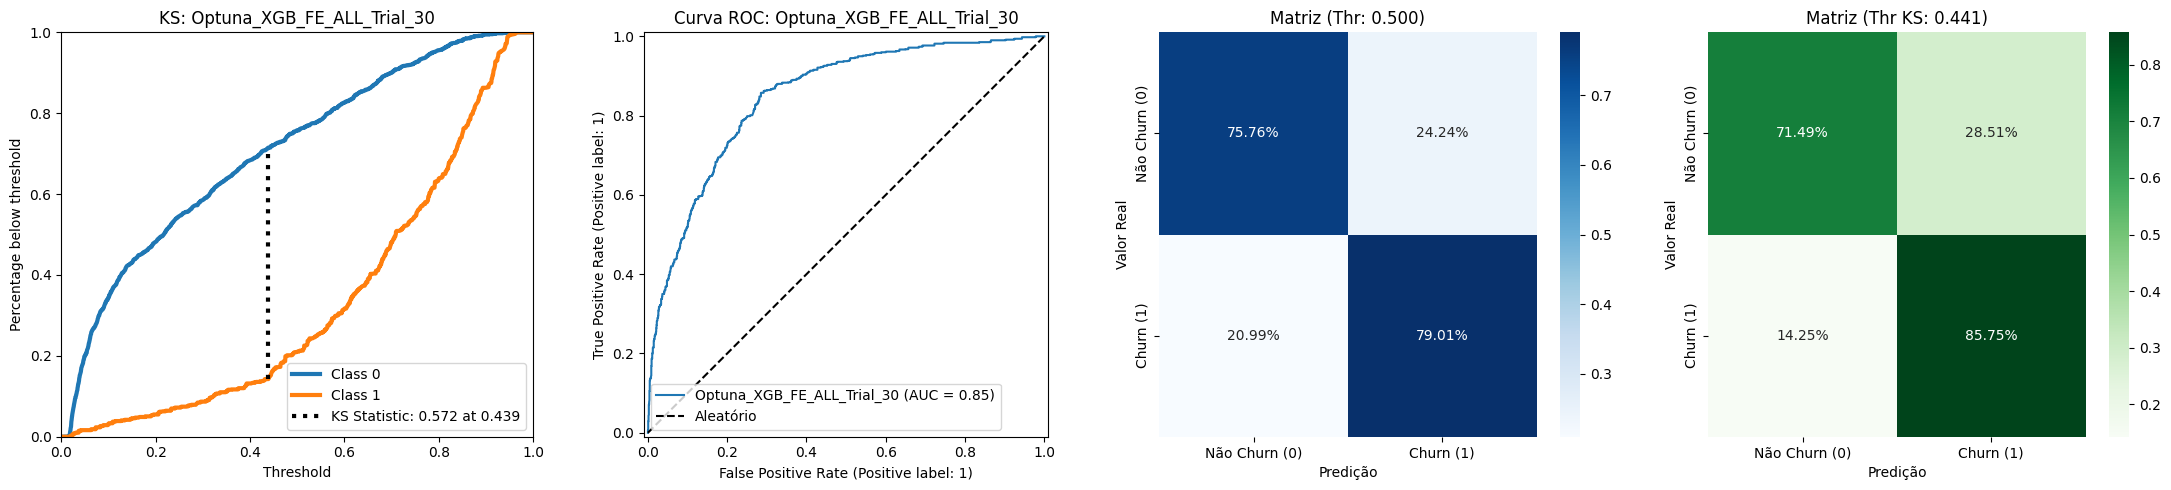

--- MÉTRICAS COM THRESHOLD PADRÃO (0.500) ---
KS: 0.5724 | AUROC: 0.8480 | MSE: 0.1577 | Log-Loss: 0.4856 | Acurácia: 0.7738
Precisão: 0.7652 | Recall: 0.7901 | F1-Score: 0.7774

               precision    recall  f1-score   support

Não Churn (0)       0.78      0.76      0.77      1291
    Churn (1)       0.77      0.79      0.78      1291

     accuracy                           0.77      2582
    macro avg       0.77      0.77      0.77      2582
 weighted avg       0.77      0.77      0.77      2582


--- MÉTRICAS COM THRESHOLD OTIMIZADO PELO KS (0.441) ---
KS: 0.5724 | AUROC: 0.8480 | Acurácia: 0.7862
Precisão: 0.7505 | Recall: 0.8575 | F1-Score: 0.8004

               precision    recall  f1-score   support

Não Churn (0)       0.83      0.71      0.77      1291
    Churn (1)       0.75      0.86      0.80      1291

     accuracy                           0.79      2582
    macro avg       0.79      0.79      0.79      2582
 weighted avg       0.79      0.79      0.79      258

In [ ]:
study_all_xgb = rodar_optuna_e_avaliar_xgb("Otimizacao_XGB_FE_ALL", X_train_all, y_train_all, X_val_all, y_val_all, "Optuna_XGB_FE_ALL_Trial")

## Ranking Final: Seleção do Modelo Definitivo

In [ ]:
def consolidar_resultados_optuna_xgb(caminho_logs_xgb):
    estudos = [
        ("Base (Sem FE)", "Otimizacao_XGB", "optuna_xgb_baseline.db"),
        ("FE 1 (Qtde Serviços)", "Otimizacao_XGB_FE1", "otimizacao_xgb_fe1.db"),
        ("FE 2 (Tenure Binning)", "Otimizacao_XGB_FE2", "otimizacao_xgb_fe2.db"),
        ("FE 3 (Proporção Gasto)", "Otimizacao_XGB_FE3", "otimizacao_xgb_fe3.db"),
        ("FE 4 (Família)", "Otimizacao_XGB_FE4", "otimizacao_xgb_fe4.db"),
        ("FE ALL (Todas as FEs)", "Otimizacao_XGB_FE_ALL", "otimizacao_xgb_fe_all.db")
    ]

    resultados = []

    caminho_csv_b7 = os.path.join(caminho_logs_xgb, "bateria_7_reg_lambda.csv")
    if os.path.exists(caminho_csv_b7):
        df_b7 = pd.read_csv(caminho_csv_b7)
        melhor_b7 = df_b7.loc[df_b7['val_ks'].idxmax()]
        resultados.append({
            "Experimento": "Manual Campeão (Bateria 7)",
            "Melhor KS": melhor_b7['val_ks'],
            "Trial ID Vencedor": melhor_b7['nome'],
            "learning_rate": melhor_b7['learning_rate'],
            "n_estimators": melhor_b7['n_estimators'],
            "max_depth": melhor_b7['max_depth'],
            "min_child_weight": melhor_b7['min_child_weight'],
            "subsample": melhor_b7['subsample'],
            "colsample_bytree": melhor_b7['colsample_bytree'],
            "reg_lambda": melhor_b7['reg_lambda']
        })

    for nome_amigavel, nome_estudo, arquivo_db in estudos:
        caminho_banco = f"sqlite:///{caminho_logs_xgb}/{arquivo_db}"
        try:
            study = optuna.load_study(study_name=nome_estudo, storage=caminho_banco)
            best_trial = study.best_trial
            linha = {
                "Experimento": nome_amigavel,
                "Melhor KS": best_trial.value,
                "Trial ID Vencedor": best_trial.number
            }
            linha.update(best_trial.params.copy())
            resultados.append(linha)
        except Exception as e:
            print(f"Aviso: Não foi possível carregar '{nome_estudo}' - {e}")

    df_ranking = pd.DataFrame(resultados)
    if not df_ranking.empty:
        df_ranking = df_ranking.sort_values(by="Melhor KS", ascending=False).reset_index(drop=True)
        caminho_csv = os.path.join(caminho_logs_xgb, "ranking_final_modelos_xgb.csv")
        df_ranking.to_csv(caminho_csv, index=False)
        print(f"Ranking consolidado salvo com sucesso em: {caminho_csv}\n")
    return df_ranking

df_ranking_final_xgb = consolidar_resultados_optuna_xgb(caminho_logs_xgb)
print("=== PÓDIO DOS MODELOS (XGBOOST) ===")
display(df_ranking_final_xgb.head(10))

Ranking consolidado salvo com sucesso em: /content/drive/MyDrive/Projeto_Churn_RN/logs/XGB_Entrega_V2/ranking_final_modelos_xgb.csv

=== PÓDIO DOS MODELOS (XGBOOST) ===


,Experimento,Melhor KS,Trial ID Vencedor,learning_rate,n_estimators,max_depth,min_child_weight,subsample,colsample_bytree,reg_lambda,colsample_bylevel,gamma,reg_alpha
0,FE 4 (Família),0.573974,87,0.069197,380,2,51,0.895096,0.915255,7.096994,0.525319,1.072066,0.181600
1,FE ALL (Todas as FEs),0.572424,30,0.058014,577,2,73,0.819334,0.508602,4.315937,0.979002,1.610621,0.116831
2,FE 2 (Tenure Binning),0.571650,50,0.038937,373,2,57,0.858083,0.970446,3.072802,0.564840,0.388225,0.227765
3,FE 3 (Proporção Gasto),0.570875,89,0.061150,1747,4,74,0.868804,0.959839,4.123384,0.685524,1.626149,0.002005
4,Base (Sem FE),0.567777,45,0.047262,645,2,44,0.761216,0.939517,2.381509,0.548231,1.200377,0.118819
5,Manual Campeão (Bateria 7),0.567002,XGB_B7_l2_0.1,0.100000,300,1,80,0.800000,1.000000,0.100000,NaN,NaN,NaN
6,FE 1 (Qtde Serviços),0.566228,27,0.116045,676,1,71,0.748531,0.928556,10.442362,0.730193,0.508476,0.223620


# Avaliação Final no Conjunto de Teste

O CAMPEÃO GERAL FOI O EXPERIMENTO: 'FE 4 (Família)'
Carregando modelo: Optuna_XGB_FE4_Trial_87.joblib

************************************************************
AVALIAÇÃO DEFINITIVA NO CONJUNTO DE TESTE (UNSEEN DATA)
************************************************************
Threshold ótimo obtido via Validação: 0.446

--- COMPARATIVO DE GENERALIZAÇÃO (TREINO vs VALIDAÇÃO vs TESTE) ---


,Conjunto,KS,AUROC,MSE (Brier),Cross-Entropy (Log-Loss)
0,Treino,0.5755,0.8653,0.1484,0.4533
1,Validação,0.5740,0.8481,0.1575,0.4859
2,Teste,0.5504,0.8435,0.1629,0.4858


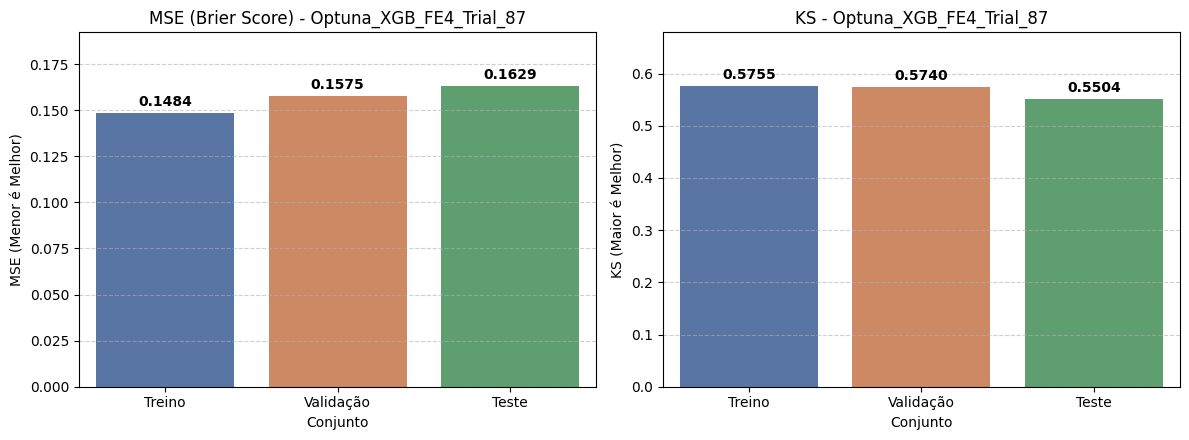

--- MÉTRICAS NO TESTE COM THRESHOLD PADRÃO (0.500) ---
KS: 0.5504 | AUROC: 0.8435 | MSE: 0.1629 | Log-Loss: 0.4858 | Acurácia: 0.7500
Precisão: 0.5179 | Recall: 0.8108 | F1-Score: 0.6320

               precision    recall  f1-score   support

Não Churn (0)       0.91      0.73      0.81      1291
    Churn (1)       0.52      0.81      0.63       465

     accuracy                           0.75      1756
    macro avg       0.72      0.77      0.72      1756
 weighted avg       0.81      0.75      0.76      1756


--- MÉTRICAS NO TESTE COM THRESHOLD OTIMIZADO (0.446) ---
KS: 0.5504 | AUROC: 0.8435 | Acurácia: 0.7221
Precisão: 0.4856 | Recall: 0.8344 | F1-Score: 0.6139

               precision    recall  f1-score   support

Não Churn (0)       0.92      0.68      0.78      1291
    Churn (1)       0.49      0.83      0.61       465

     accuracy                           0.72      1756
    macro avg       0.70      0.76      0.70      1756
 weighted avg       0.80      0.72      0.7

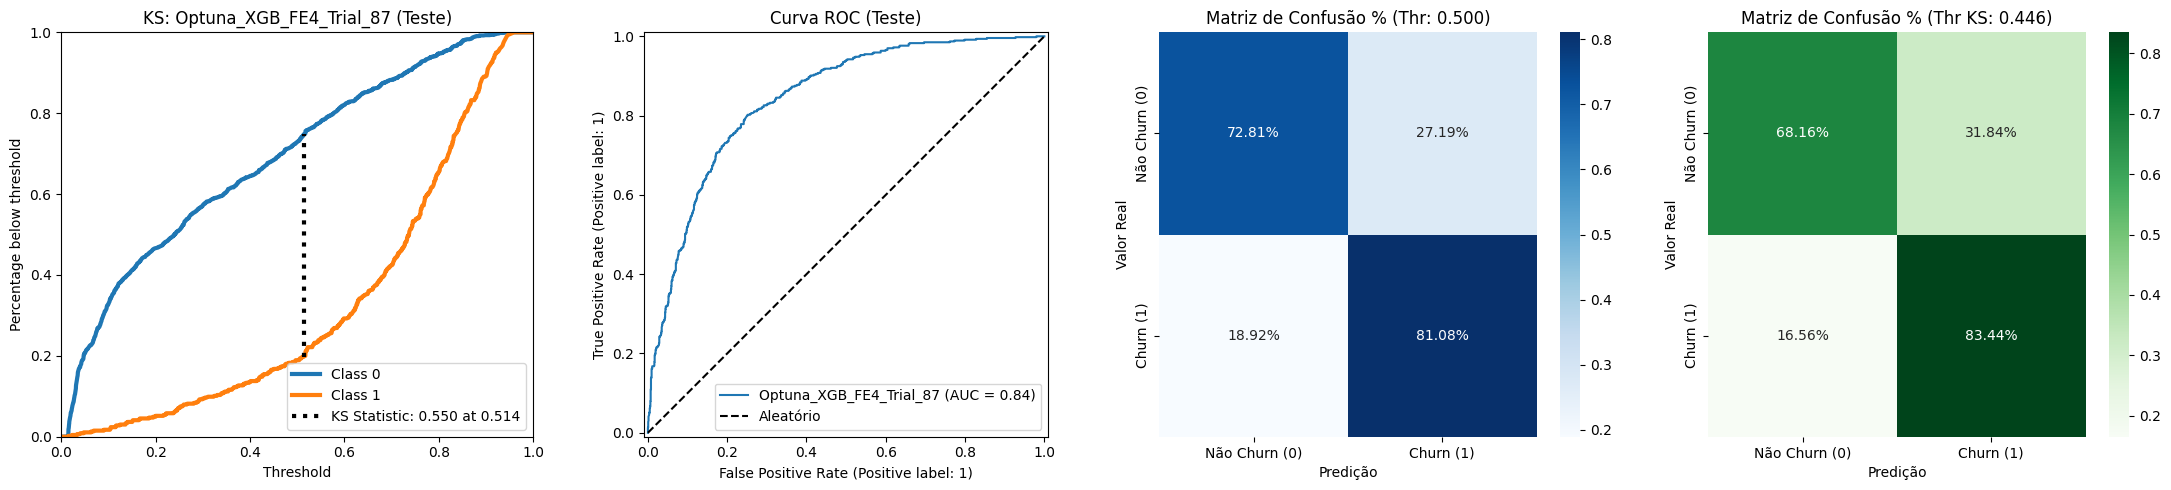

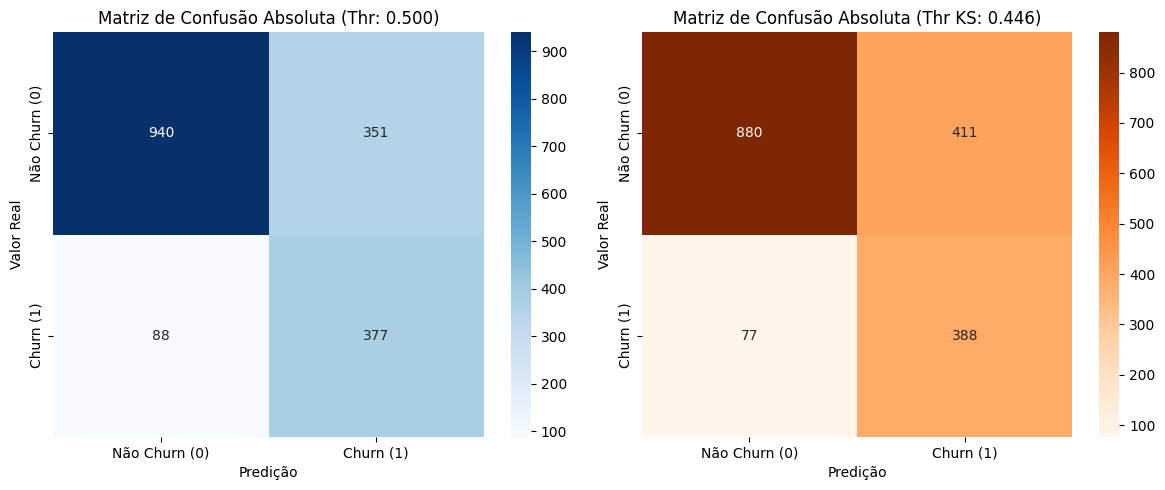

In [ ]:
melhor_modelo_info = df_ranking_final_xgb.iloc[0]
experimento_campeao = melhor_modelo_info['Experimento']
trial_id = melhor_modelo_info['Trial ID Vencedor']

mapa_experimentos_xgb = {
    "Manual Campeão (Bateria 7)": {"X_train": X_train_xgb, "y_train": y_train_xgb, "X_val": X_val_xgb, "y_val": y_val_xgb, "X_test": X_test_xgb, "y_test": y_test_xgb, "prefixo": ""},
    "Base (Sem FE)": {"X_train": X_train_xgb, "y_train": y_train_xgb, "X_val": X_val_xgb, "y_val": y_val_xgb, "X_test": X_test_xgb, "y_test": y_test_xgb, "prefixo": "Optuna_Trial_"},
    "FE 1 (Qtde Serviços)": {"X_train": X_train_fe1, "y_train": y_train_fe1, "X_val": X_val_fe1, "y_val": y_val_fe1, "X_test": X_test_fe1, "y_test": y_test_fe1, "prefixo": "Optuna_XGB_FE1_Trial_"},
    "FE 2 (Tenure Binning)": {"X_train": X_train_fe2, "y_train": y_train_fe2, "X_val": X_val_fe2, "y_val": y_val_fe2, "X_test": X_test_fe2, "y_test": y_test_fe2, "prefixo": "Optuna_XGB_FE2_Trial_"},
    "FE 3 (Proporção Gasto)": {"X_train": X_train_fe3, "y_train": y_train_fe3, "X_val": X_val_fe3, "y_val": y_val_fe3, "X_test": X_test_fe3, "y_test": y_test_fe3, "prefixo": "Optuna_XGB_FE3_Trial_"},
    "FE 4 (Família)": {"X_train": X_train_fe4, "y_train": y_train_fe4, "X_val": X_val_fe4, "y_val": y_val_fe4, "X_test": X_test_fe4, "y_test": y_test_fe4, "prefixo": "Optuna_XGB_FE4_Trial_"},
    "FE ALL (Todas as FEs)": {"X_train": X_train_all, "y_train": y_train_all, "X_val": X_val_all, "y_val": y_val_all, "X_test": X_test_all, "y_test": y_test_all, "prefixo": "Optuna_XGB_FE_ALL_Trial_"}
}

config_vencedor = mapa_experimentos_xgb[experimento_campeao]
X_train_campeao = config_vencedor["X_train"]
y_train_campeao = config_vencedor["y_train"]
X_val_campeao = config_vencedor["X_val"]
y_val_campeao = config_vencedor["y_val"]
X_test_campeao = config_vencedor["X_test"]
y_test_campeao = config_vencedor["y_test"]

if isinstance(trial_id, (int, np.integer)) or str(trial_id).isdigit():
    nome_modelo_salvo = f"{config_vencedor['prefixo']}{int(trial_id)}"
else:
    nome_modelo_salvo = str(trial_id)

print(f"O CAMPEÃO GERAL FOI O EXPERIMENTO: '{experimento_campeao}'")
print(f"Carregando modelo: {nome_modelo_salvo}.joblib")
print("\n" + "*"*60)
print("AVALIAÇÃO DEFINITIVA NO CONJUNTO DE TESTE (UNSEEN DATA)")
print("*"*60)

caminho_arquivo = os.path.join(caminho_modelos_xgb, f"{nome_modelo_salvo}.joblib")
modelo_campeao = joblib.load(caminho_arquivo)

# 1. Avaliação em Treino e Validação (Threshold ótimo extraído APENAS da Validação)
probs_1_train = modelo_campeao.predict_proba(X_train_campeao)[:, 1]
scores_train = get_scores_churn(np.array(y_train_campeao), probs_1_train)

probs_1_val = modelo_campeao.predict_proba(X_val_campeao)[:, 1]
scores_val = get_scores_churn(np.array(y_val_campeao), probs_1_val)
optimal_thresh = scores_val['optimal_threshold']
print(f"Threshold ótimo obtido via Validação: {optimal_thresh:.3f}\n")

# 2. Avaliação definitiva no Teste (desbalanceado / mundo real)
probs_1_test = modelo_campeao.predict_proba(X_test_campeao)[:, 1]
y_true_test = np.array(y_test_campeao)
probs_0_test = 1 - probs_1_test
y_pred_scores = np.column_stack((probs_0_test, probs_1_test))

scores_default_test = get_scores_churn(y_true_test, probs_1_test, threshold=0.5)
scores_optimal_test = get_scores_churn(y_true_test, probs_1_test, threshold=optimal_thresh)

y_pred_default = (probs_1_test >= 0.5).astype(int)
y_pred_otimizado = (probs_1_test >= optimal_thresh).astype(int)

# 3. Tabela e Gráficos de Generalização (Treino vs Validação vs Teste)
df_generalizacao = pd.DataFrame([
    {"Conjunto": "Treino",    "KS": scores_train['ks_stat'],        "AUROC": scores_train['roc_auc'],        "MSE (Brier)": scores_train['mse'],        "Cross-Entropy (Log-Loss)": scores_train['log_loss']},
    {"Conjunto": "Validação", "KS": scores_val['ks_stat'],          "AUROC": scores_val['roc_auc'],          "MSE (Brier)": scores_val['mse'],          "Cross-Entropy (Log-Loss)": scores_val['log_loss']},
    {"Conjunto": "Teste",     "KS": scores_default_test['ks_stat'], "AUROC": scores_default_test['roc_auc'], "MSE (Brier)": scores_default_test['mse'], "Cross-Entropy (Log-Loss)": scores_default_test['log_loss']}
])
print("--- COMPARATIVO DE GENERALIZAÇÃO (TREINO vs VALIDAÇÃO vs TESTE) ---")
display(df_generalizacao.round(4))

fig_mse, axes_mse = plt.subplots(1, 2, figsize=(12, 4.5))
sns.barplot(data=df_generalizacao, x="Conjunto", y="MSE (Brier)", hue="Conjunto",
            palette=["#4C72B0", "#DD8452", "#55A868"], legend=False, ax=axes_mse[0])
for p in axes_mse[0].patches:
    axes_mse[0].annotate(f"{p.get_height():.4f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                         ha='center', va='center', xytext=(0, 8), textcoords='offset points', fontweight='bold')
axes_mse[0].set_ylim(0, df_generalizacao["MSE (Brier)"].max() * 1.18)
axes_mse[0].set_title(f"MSE (Brier Score) - {nome_modelo_salvo}")
axes_mse[0].set_ylabel("MSE (Menor é Melhor)")
axes_mse[0].grid(axis='y', linestyle='--', alpha=0.6)

sns.barplot(data=df_generalizacao, x="Conjunto", y="KS", hue="Conjunto",
            palette=["#4C72B0", "#DD8452", "#55A868"], legend=False, ax=axes_mse[1])
for p in axes_mse[1].patches:
    axes_mse[1].annotate(f"{p.get_height():.4f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                         ha='center', va='center', xytext=(0, 8), textcoords='offset points', fontweight='bold')
axes_mse[1].set_ylim(0, df_generalizacao["KS"].max() * 1.18)
axes_mse[1].set_title(f"KS - {nome_modelo_salvo}")
axes_mse[1].set_ylabel("KS (Maior é Melhor)")
axes_mse[1].grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# 4. Relatórios de Classificação e Matrizes de Confusão (% e Absolutas)
print(f"--- MÉTRICAS NO TESTE COM THRESHOLD PADRÃO (0.500) ---")
print(f"KS: {scores_default_test['ks_stat']:.4f} | AUROC: {scores_default_test['roc_auc']:.4f} | MSE: {scores_default_test['mse']:.4f} | Log-Loss: {scores_default_test['log_loss']:.4f} | Acurácia: {scores_default_test['accuracy']:.4f}")
print(f"Precisão: {scores_default_test['precision']:.4f} | Recall: {scores_default_test['recall']:.4f} | F1-Score: {scores_default_test['f1_score']:.4f}\n")
print(classification_report(y_true_test, y_pred_default, target_names=['Não Churn (0)', 'Churn (1)']))

print(f"\n--- MÉTRICAS NO TESTE COM THRESHOLD OTIMIZADO ({optimal_thresh:.3f}) ---")
print(f"KS: {scores_optimal_test['ks_stat']:.4f} | AUROC: {scores_optimal_test['roc_auc']:.4f} | Acurácia: {scores_optimal_test['accuracy']:.4f}")
print(f"Precisão: {scores_optimal_test['precision']:.4f} | Recall: {scores_optimal_test['recall']:.4f} | F1-Score: {scores_optimal_test['f1_score']:.4f}\n")
print(classification_report(y_true_test, y_pred_otimizado, target_names=['Não Churn (0)', 'Churn (1)']))

fig, axes = plt.subplots(1, 4, figsize=(22, 5))
skplt.metrics.plot_ks_statistic(y_true_test, y_pred_scores, ax=axes[0], title=f"KS: {nome_modelo_salvo} (Teste)")

RocCurveDisplay.from_predictions(y_true_test, probs_1_test, ax=axes[1], name=nome_modelo_salvo)
axes[1].set_title("Curva ROC (Teste)")
axes[1].plot([0, 1], [0, 1], 'k--', label='Aleatório')
axes[1].legend()

cm_norm_default = confusion_matrix(y_true_test, y_pred_default, normalize='true')
sns.heatmap(cm_norm_default, annot=True, fmt=".2%", cmap="Blues", ax=axes[2],
            xticklabels=['Não Churn (0)', 'Churn (1)'], yticklabels=['Não Churn (0)', 'Churn (1)'])
axes[2].set_title("Matriz de Confusão % (Thr: 0.500)")
axes[2].set_ylabel("Valor Real")
axes[2].set_xlabel("Predição")

cm_norm_optimal = confusion_matrix(y_true_test, y_pred_otimizado, normalize='true')
sns.heatmap(cm_norm_optimal, annot=True, fmt=".2%", cmap="Greens", ax=axes[3],
            xticklabels=['Não Churn (0)', 'Churn (1)'], yticklabels=['Não Churn (0)', 'Churn (1)'])
axes[3].set_title(f"Matriz de Confusão % (Thr KS: {optimal_thresh:.3f})")
axes[3].set_ylabel("Valor Real")
axes[3].set_xlabel("Predição")

plt.tight_layout()
plt.show()

cm_abs_default = confusion_matrix(y_true_test, y_pred_default)
cm_abs_optimal = confusion_matrix(y_true_test, y_pred_otimizado)
fig2, axes2 = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(cm_abs_default, annot=True, fmt="d", cmap="Blues", ax=axes2[0],
            xticklabels=['Não Churn (0)', 'Churn (1)'], yticklabels=['Não Churn (0)', 'Churn (1)'])
axes2[0].set_title("Matriz de Confusão Absoluta (Thr: 0.500)")
axes2[0].set_ylabel("Valor Real")
axes2[0].set_xlabel("Predição")

sns.heatmap(cm_abs_optimal, annot=True, fmt="d", cmap="Oranges", ax=axes2[1],
            xticklabels=['Não Churn (0)', 'Churn (1)'], yticklabels=['Não Churn (0)', 'Churn (1)'])
axes2[1].set_title(f"Matriz de Confusão Absoluta (Thr KS: {optimal_thresh:.3f})")
axes2[1].set_ylabel("Valor Real")
axes2[1].set_xlabel("Predição")

plt.tight_layout()
plt.show()